# Speed Shows Up, Breaks Don't
## What Combine sensor tracking does — and does not — tell us about NFL wide-receiver separation
*NFL Big Data Bowl 2027 — Combine to NFL Performance*

**Abstract.** We link 10 Hz Combine drill tracking for 106 wide receivers (2023–2025 draft classes) to
30,566 regular-season routes and 34,807 game-tracking route plays via `nfl_id`. A plant-and-break detector finds
route breaks in 95–100% of Combine Comeback, Curl and Slot-Strike reps and on NFL hitch routes, which lets us
measure the *same* mechanics in both settings. We test a pre-specified hypothesis: faster deceleration into and
re-acceleration out of Combine breaks predicts **Separation Over Expected (SOE)**, a route-, coverage- and
cushion-adjusted separation metric where positive means more open than expected.

**Findings.**
1. **Top speed transfers.** Combine-tracked top speed correlates r = 0.48 with NFL GO-route top speed, more strongly than the official 40 does (|r| = 0.36). In 93 matched pairs of WRs with the same 40 (±0.02 s), the tracked-faster player was also faster on NFL GO routes **70% of the time** (permutation p = 0.03).
2. **Break mechanics do not transfer.** Single-session Combine break metrics are unreliable (index reliability 0.38) and unrelated to NFL hitch-break mechanics (r = 0.01).
3. **No positive association with separation.** The break index shows no positive association with SOE (−0.034 yd/route per SD, 95% CI −0.073 to +0.005, n = 56). The study was powered only to detect large effects.
4. **In games, neither trait buys separation at the throw.** Hitch-break deceleration does not predict hitch separation on other plays (r = −0.02). GO-route speed is, if anything, associated with *less* GO-route separation.
5. **No out-of-sample gain.** Even with the SOE target rebuilt inside every fold, no tracking feature reliably improves out-of-sample prediction over traditional Combine metrics, for unseen players or for unseen draft classes.

**Research question.** *Does a WR's Combine-measured ability to get in and out of a route break carry into NFL
games, and does it add information about regular-season separation beyond traditional Combine measurements?*

## Motivation and football relevance

Separation is the currency of receiver evaluation, and "getting in and out of breaks" is the trait scouts most
often credit for it. Traditional Combine testing measures straight-line speed (40, 10-yd split), explosiveness
(jumps) and generic change of direction (3-cone, shuttle, which most WRs now skip: 69% missing in this cohort). None
of these measures a route break. Combine sensor tracking makes it possible to measure the break itself in
WR position drills, and the competition's game tracking makes it possible to check whether the same mechanic appears
on NFL Sundays.

Our design deliberately separates three questions, because a scout needs all three answered before trusting a
Combine number:
1. **Measurement:** does the Combine metric measure a stable trait (reliability)?
2. **Transfer:** does the trait reappear in NFL game tracking (Combine tracking → game tracking)?
3. **Value:** is it associated with, and does it improve prediction of, regular-season separation beyond what
   the stopwatch already tells us?

## 1. Setup

All paths are discovered at run time. On Kaggle the competition data is mounted under
`/kaggle/input/...`; locally the notebook falls back to `./nfl-big-data-bowl-2027`.
Every random process uses `SEED`. Figures and tables are written to `OUT`.

In [1]:
import os, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import RepeatedKFold, LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 2027
np.random.seed(SEED)
pd.set_option("display.max_columns", 80); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

CANDIDATES = [
    Path("/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027"),
    Path("/kaggle/input/nfl-big-data-bowl-2027"),
    Path("nfl-big-data-bowl-2027"),
]
BASE = next((p for p in CANDIDATES if (p / "players.csv").exists()), None)
if BASE is None:
    hits = list(Path("/kaggle/input").rglob("players.csv")) if Path("/kaggle/input").exists() else []
    BASE = hits[0].parent if hits else None
assert BASE is not None, "Competition data not found - edit CANDIDATES."
OUT = Path("/kaggle/working/outputs") if Path("/kaggle/working").exists() else Path("outputs")
(OUT / "figures").mkdir(parents=True, exist_ok=True); (OUT / "tables").mkdir(parents=True, exist_ok=True)
print("Data:", BASE.resolve()); print("Outputs:", OUT.resolve())

# Plot style: one validated categorical order (blue, orange, aqua), recessive grey ink.
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": INK2,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "lines.linewidth": 2, "savefig.dpi": 130, "savefig.bbox": "tight",
})
KEY = {}          # every number quoted in the write-up is stored here and exported
def savefig(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png"); plt.show()
def save_table(df, name, index=False):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=index); return df

Data: /home/sonia/Documents/DAILY_USE_TASK/Data_science_project/nfl-big-data-bowl-2027
Outputs: /home/sonia/Documents/DAILY_USE_TASK/Data_science_project/outputs


## 2. Dataset inventory and data dictionary

Every file in the competition directory is profiled programmatically. Files above ~200 MB
(the three regular-season tracking files) are streamed in 2M-row chunks so the notebook runs
within Kaggle memory limits; for those, row counts and missingness are exact, while
unique-value counts are computed only for identifier columns.

In [2]:
ID_PATTERNS = ("nfl_id", "game_id", "play_id", "event_id", "season", "week", "draft_year",
               "attempt", "drill", "game_key")
ROLE = {
    "players.csv": ("Player master: position, draft year, draft slot", "Primary (cohort)"),
    "combine_results.csv": ("Traditional Combine measurements (1 row/prospect)", "Primary (baseline features)"),
    "combine_tracking.csv": ("10 Hz Combine drill tracking (player + ball)", "Primary (movement features)"),
    "player_play.csv": ("1 row per player per play; NGS route & separation fields", "Primary (outcome + context)"),
    "games.csv": ("Game metadata: season, week, season type", "Primary (REG filter)"),
    "game_tracking_2023.csv": ("10 Hz in-game tracking, prospects only, 2023 season", "Primary (game movement)"),
    "game_tracking_2024.csv": ("10 Hz in-game tracking, prospects only, 2024 season", "Primary (game movement)"),
    "game_tracking_2025.csv": ("10 Hz in-game tracking, prospects only, 2025 season", "Primary (game movement)"),
    "player_career_successes.csv": ("Career snaps / starts / honours (1 row/prospect)", "Secondary outcome"),
}

def profile_csv(path, chunksize=2_000_000):
    size_mb = path.stat().st_size / 1e6
    if size_mb < 200:
        df = pd.read_csv(path, low_memory=False)
        n, dtypes, miss = len(df), df.dtypes.astype(str), df.isna().mean() * 100
        nuniq = df.nunique()
    else:
        n, miss_cnt, dtypes, uniq = 0, None, None, {}
        for ch in pd.read_csv(path, chunksize=chunksize, low_memory=False):
            n += len(ch)
            m = ch.isna().sum(); miss_cnt = m if miss_cnt is None else miss_cnt + m
            dtypes = ch.dtypes.astype(str) if dtypes is None else dtypes
            for c in ch.columns:
                if c in ("game_id", "nfl_id"):
                    uniq.setdefault(c, set()).update(ch[c].unique())
            uniq.setdefault("game_play", set()).update(zip(ch.game_id, ch.play_id))
        miss = miss_cnt / n * 100
        nuniq = pd.Series({c: len(uniq[c]) if c in uniq else np.nan for c in dtypes.index})
        nuniq["(game_id, play_id)"] = len(uniq["game_play"])
    dd = pd.DataFrame({"dtype": dtypes, "missing_pct": miss.round(2), "n_unique": nuniq.reindex(dtypes.index)})
    dd.index.name = "column"
    ids = [c for c in dtypes.index if any(p in c for p in ID_PATTERNS)]
    return dict(file=path.name, format=path.suffix[1:], size_mb=round(size_mb, 1), rows=n,
                cols=len(dtypes), id_columns=", ".join(ids),
                cols_with_missing=int((miss > 0).sum()),
                n_game_plays=int(nuniq.get("(game_id, play_id)", np.nan)) if size_mb >= 200 else None), dd

t0 = time.time()
inventory, dictionary = [], {}
for f in sorted(BASE.iterdir()):
    if f.suffix.lower() != ".csv":
        print("Non-CSV file found (not profiled):", f.name); continue
    row, dd = profile_csv(f)
    row["content"], row["use"] = ROLE.get(f.name, ("Unrecognised file", "Inspect"))
    inventory.append(row); dictionary[f.name] = dd
inventory = pd.DataFrame(inventory)
save_table(inventory, "01_dataset_inventory")
pd.concat(dictionary, names=["file"]).to_csv(OUT / "tables" / "02_data_dictionary.csv")
print(f"Profiled {len(inventory)} files in {time.time()-t0:.0f}s")
display(inventory[["file", "size_mb", "rows", "cols", "id_columns", "content", "use"]])

Profiled 9 files in 45s


,file,size_mb,rows,cols,id_columns,content,use
0,combine_results.csv,0.000,510,18,"draft_year, nfl_id",Traditional Combine measurements (1 row/prospect),Primary (baseline features)
1,combine_tracking.csv,83.800,463189,14,"draft_year, event_id, nfl_id, drill_type, dril...",10 Hz Combine drill tracking (player + ball),Primary (movement features)
2,game_tracking_2023.csv,335.500,3665443,12,"game_id, play_id, nfl_id","10 Hz in-game tracking, prospects only, 2023 s...",Primary (game movement)
3,game_tracking_2024.csv,718.000,7827944,12,"game_id, play_id, nfl_id","10 Hz in-game tracking, prospects only, 2024 s...",Primary (game movement)
4,game_tracking_2025.csv,"1,022.600",11160903,12,"game_id, play_id, nfl_id","10 Hz in-game tracking, prospects only, 2025 s...",Primary (game movement)
5,games.csv,0.000,1002,7,"game_id, game_key, season, season_type, week","Game metadata: season, week, season type",Primary (REG filter)
6,player_career_successes.csv,0.000,510,9,nfl_id,Career snaps / starts / honours (1 row/prospect),Secondary outcome
7,player_play.csv,146.900,314197,64,"game_id, play_id, nfl_id",1 row per player per play; NGS route & separat...,Primary (outcome + context)
8,players.csv,0.000,510,10,"nfl_id, draft_year","Player master: position, draft year, draft slot",Primary (cohort)


In [3]:
# Data dictionary for the files that drive the analysis (full dictionary exported to CSV).
for f in ["combine_tracking.csv", "game_tracking_2025.csv", "combine_results.csv", "games.csv"]:
    print(f"\n=== {f}"); display(dictionary[f].T)
pp_dict = dictionary["player_play.csv"]
print("\n=== player_play.csv - receiving / route columns")
display(pp_dict.loc[["route_ran", "separation_at_pass_forward", "cushion", "target", "lined_up_position",
                     "team_coverage_type", "team_coverage_man_zone", "pass_result", "rec_yards"]])


=== combine_tracking.csv


column,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
dtype,int64,str,int64,str,str,str,str,int64,float64,float64,float64,float64,float64,float64
missing_pct,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
n_unique,3,6310,510,2,429596,9,56,17,178985,179841,182182,371251,179472,429809



=== game_tracking_2025.csv


column,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
dtype,int64,int64,int64,str,float64,float64,float64,float64,float64,float64,float64,str
missing_pct,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,93.410
n_unique,334.000,NaN,448.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



=== combine_results.csv


column,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
dtype,int64,int64,str,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,float64,float64
missing_pct,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,16.670,16.860,14.120,17.060,64.710,60.590,62.350,0.000,0.200,0.200
n_unique,3,510,5,95,149,27,60,114,46,106,41,42,95,88,25,48,44,42



=== games.csv


column,game_id,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
dtype,int64,int64,int64,str,int64,str,str
missing_pct,0.000,0.000,0.000,0.000,0.000,0.000,0.000
n_unique,1002,1002,3,3,23,33,33



=== player_play.csv - receiving / route columns


,dtype,missing_pct,n_unique
column,,,
route_ran,str,83.030,12
separation_at_pass_forward,float64,85.120,30351
cushion,float64,66.980,1461
target,bool,0.000,2
lined_up_position,str,0.440,17
team_coverage_type,str,12.390,8
team_coverage_man_zone,str,12.390,2
pass_result,str,32.980,5
rec_yards,float64,98.010,88


**What the inventory shows.**
- **Nine CSVs, all used.** `players`, `combine_results` and `player_career_successes` each hold exactly one row per prospect (510 prospects, all positions, 2023–2025 drafts).
- **Combine tracking:** 463,189 frames at 10 Hz with no missing values. 32,095 of those frames are `BALL` entities and are excluded.
- **Season tracking:** 3.7M / 7.8M / 11.2M frames for 2023 / 2024 / 2025. The files contain **only the prospects themselves** (156, 318 and 448 players; no defenders and no ball), so separation cannot be recomputed from raw tracking and must come from `player_play`. `event` is 93% missing because it is only populated on the frame where an event occurs.
- **`player_play`** has one row per prospect per play (314,197 rows × 64 columns). It carries the NGS receiving fields `route_ran`, `separation_at_pass_forward` and `cushion`, plus coverage context.
- **`games`** contains preseason and postseason games as well as regular-season ones, so filtering on `season_type` is required.

## 3. Proving the Combine-to-game linkage

The required chain is

**Combine tracking → drill/attempt features → `nfl_id` → regular-season player-play rows (+ game tracking aggregated to player-play) → separation outcome.**

Each join below uses pandas `validate=` so an unexpected many-to-many join raises an error rather
than silently multiplying rows. Frame-level game tracking is **never** joined to play rows directly:
it is first reduced to one row per player-play.

In [4]:
players = pd.read_csv(BASE / "players.csv")
combine = pd.read_csv(BASE / "combine_results.csv")
career  = pd.read_csv(BASE / "player_career_successes.csv")
games   = pd.read_csv(BASE / "games.csv")
for name, d, k in [("players", players, ["nfl_id"]), ("combine_results", combine, ["nfl_id"]),
                   ("career", career, ["nfl_id"]), ("games", games, ["game_id"])]:
    print(f"{name:16s} rows={len(d):5d}  duplicate keys={d.duplicated(k).sum()}")

pc = players.merge(combine, on="nfl_id", how="outer", validate="one_to_one",
                   suffixes=("", "_cmb"), indicator=True)
print("\nplayers <-> combine_results:", pc["_merge"].value_counts().to_dict())
print("draft_year agreement:", (pc.draft_year == pc.draft_year_cmb).mean())
pos_check = pd.crosstab(pc.nfl_position.where(pc.nfl_position.eq("WR"), "other"),
                        pc.combine_position.where(pc.combine_position.eq("WR"), "other"))
display(pos_check)

players          rows=  510  duplicate keys=0
combine_results  rows=  510  duplicate keys=0
career           rows=  510  duplicate keys=0
games            rows= 1002  duplicate keys=0

players <-> combine_results: {'both': 510, 'left_only': 0, 'right_only': 0}
draft_year agreement: 1.0


combine_position,WR,other
nfl_position,,
WR,106,0
other,1,403


In [5]:
# ---- Cohort: NFL-listed wide receivers (all have a WR Combine record) -----------------------
wr = pc.loc[pc.nfl_position.eq("WR")].copy()
mismatch = pc.loc[pc.combine_position.eq("WR") & pc.nfl_position.ne("WR"), ["nfl_id", "display_name", "nfl_position"]]
print("Combine-WR listed at another NFL position (excluded):"); display(mismatch)
WR_IDS = set(wr.nfl_id)
print("WR cohort:", len(WR_IDS), "| by draft year:", wr.draft_year.value_counts().sort_index().to_dict())

# ---- Combine tracking ---------------------------------------------------------------------------
ct = pd.read_csv(BASE / "combine_tracking.csv")
print("\ncombine_tracking rows:", len(ct), "| entity types:", ct.entity_type.value_counts().to_dict())
# Two drill names are spelled two ways in different years; harmonise them before aggregation.
DRILL_ALIASES = {"SPEED_OUT_LEFT": "SPEED_OUT_ROUTE_LEFT", "OVER_THE_SHOULDER_ADJUST": "OVER_SHOULDER_ADJUST",
                 "LINE": "LINE_DRILL", "PASS_PRO-MIRROR_DRILL": "PASS_PRO_MIRROR_DRILL"}
print("Alias years:", ct[ct.drill_name.isin(DRILL_ALIASES)].groupby("drill_name").draft_year.unique().to_dict())
ct["drill_name"] = ct["drill_name"].replace(DRILL_ALIASES)
ctw = ct[ct.entity_type.eq("PLAYER") & ct.nfl_id.isin(WR_IDS)].copy()
chk = ctw[["nfl_id", "draft_year"]].drop_duplicates().merge(
    wr[["nfl_id", "draft_year"]], on="nfl_id", suffixes=("_trk", ""), validate="one_to_one")
print("WRs with Combine tracking:", ctw.nfl_id.nunique(), "| draft_year agreement:",
      (chk.draft_year_trk == chk.draft_year).mean())
ATT = ["nfl_id", "event_id", "drill_name", "attempt"]
ctw = ctw.sort_values(ATT + ["time"]).reset_index(drop=True)
print("Duplicate (attempt, timestamp) frames:", ctw.duplicated(ATT + ["time"]).sum())

Combine-WR listed at another NFL position (excluded):


,nfl_id,display_name,nfl_position
93,56062,Elijah Higgins,TE


WR cohort: 106 | by draft year: {2023: 38, 2024: 31, 2025: 37}



combine_tracking rows: 463189 | entity types: {'PLAYER': 431094, 'BALL': 32095}
Alias years: {'LINE': array([2023]), 'OVER_THE_SHOULDER_ADJUST': array([2023]), 'PASS_PRO-MIRROR_DRILL': array([2025, 2024]), 'SPEED_OUT_LEFT': array([2024])}
WRs with Combine tracking: 106 | draft_year agreement: 1.0
Duplicate (attempt, timestamp) frames: 0


In [6]:
# ---- Regular-season play-level data -----------------------------------------------------------
PP_COLS = ["game_id", "play_id", "nfl_id", "team_abbr", "lined_up_position", "down", "yards_to_go",
           "quarter", "offense_formation", "receiver_alignment", "pass_result", "play_nullified_by_penalty",
           "team_coverage_man_zone", "team_coverage_type", "target", "route_ran",
           "separation_at_pass_forward", "cushion", "rec_yards"]
pp = pd.read_csv(BASE / "player_play.csv", usecols=PP_COLS, low_memory=False)
print("player_play rows:", len(pp), "| duplicate (game, play, player):", pp.duplicated(["game_id", "play_id", "nfl_id"]).sum())
pp = pp.merge(games[["game_id", "season", "season_type", "week"]], on="game_id", how="left", validate="many_to_one")
print("rows with unmatched game_id:", pp.season.isna().sum())
ppw = pp[pp.nfl_id.isin(WR_IDS)].merge(wr[["nfl_id", "draft_year"]], on="nfl_id", validate="many_to_one")
print("WR rows:", len(ppw), "| WRs:", ppw.nfl_id.nunique(),
      "| rows with season < draft_year:", int((ppw.season < ppw.draft_year).sum()))
display(pd.crosstab(ppw.season_type, ppw.season, margins=True))
print("Separation populated:", ppw.groupby(ppw.route_ran.notna()).separation_at_pass_forward
      .apply(lambda s: f"{s.notna().sum()} of {len(s)}").to_dict(), "(keyed by 'route recorded')")
print("Separation populated by target flag:", ppw[ppw.route_ran.notna()].groupby("target")
      .separation_at_pass_forward.apply(lambda s: f"{s.notna().sum()} of {len(s)}").to_dict())
reg_routes = ppw[ppw.season_type.eq("REG") & ppw.route_ran.notna()].copy()
print("Nullified plays among REG routes:", reg_routes.play_nullified_by_penalty.eq("Y").sum())

player_play rows: 314197 | duplicate (game, play, player): 0
rows with unmatched game_id: 0
WR rows: 42806 | WRs: 105 | rows with season < draft_year: 0


season,2023,2024,2025,All
season_type,,,,
POST,267,415,1135,1817
PRE,1503,2019,2578,6100
REG,7416,12348,15125,34889
All,9186,14782,18838,42806


Separation populated: {True: '37525 of 42806'} (keyed by 'route recorded')
Separation populated by target flag: {False: '29432 of 34713', True: '8093 of 8093'}
Nullified plays among REG routes: 0


In [7]:
# ---- Game tracking: stream, keep only cohort REG route plays, reduce to 1 row per player-play ----
TRK_KEY = ["game_id", "play_id", "nfl_id"]
keys = reg_routes[TRK_KEY].drop_duplicates()
frames, frame_stats = [], []
for yr in [2023, 2024, 2025]:
    t0, n_all = time.time(), 0
    for ch in pd.read_csv(BASE / f"game_tracking_{yr}.csv", chunksize=2_000_000,
                          usecols=TRK_KEY + ["time", "x", "y", "s", "a", "event"]):
        n_all += len(ch)
        frames.append(ch.merge(keys, on=TRK_KEY, how="inner"))
    frame_stats.append({"season_file": yr, "frames_in_file": n_all, "secs": round(time.time() - t0, 1)})
gtr = pd.concat(frames, ignore_index=True); del frames
gtr = gtr.sort_values(TRK_KEY + ["time"]).reset_index(drop=True)
display(pd.DataFrame(frame_stats))
print("Kept frames:", len(gtr), "| duplicate (play, player, time):", gtr.duplicated(TRK_KEY + ["time"]).sum())
dt = pd.to_datetime(gtr.time).groupby([gtr.game_id, gtr.play_id, gtr.nfl_id]).diff().dt.total_seconds()
print("Game frame interval (s):", dt.round(2).value_counts().head(3).to_dict())
dtc = pd.to_datetime(ctw.time).groupby([ctw[c] for c in ATT]).diff().dt.total_seconds()
print("Combine frame interval (s):", dtc.round(2).value_counts().head(3).to_dict())
n_trk_plays = gtr[TRK_KEY].drop_duplicates().shape[0]
print(f"REG WR route plays with tracking frames: {n_trk_plays} of {len(keys)} ({n_trk_plays/len(keys):.1%})")

,season_file,frames_in_file,secs
0,2023,3665443,5.300
1,2024,7827944,10.900
2,2025,11160903,17.200


Kept frames: 2638624 | duplicate (play, player, time): 0


Game frame interval (s): {0.1: 2603806}
Combine frame interval (s): {0.1: 106650}
REG WR route plays with tracking frames: 34818 of 34889 (99.8%)


**Linkage verdict: the chain is valid and loss-free where it should be.**
- **Identity tables:** `players` ↔ `combine_results` is a clean 1:1 match on `nfl_id`, and draft years agree for 100% of prospects.
- **Cohort:** all 106 NFL-listed WRs tested as WRs. One Combine WR (Elijah Higgins) is listed as a TE in the NFL and is excluded.
- **Combine tracking:** every cohort WR has tracking, with 100% draft-year agreement. Four drill names are spelled differently in different years (e.g. `SPEED_OUT_LEFT` in 2024); these were harmonised before aggregation, a detail the earlier notebook's `"ROUTE"` string filter partly missed.
- **Play-level data:** 105 WRs have play rows. No row predates the player's draft year, and no regular-season route play is nullified.
- **Separation coverage:** separation is populated on **every targeted route and 85% of non-targeted routes**. It is therefore a measurement of every pass route, not a statistic for targeted plays only, which gives about 4.6× more observations than a target-based outcome.
- **Game tracking:** 99.8% of regular-season WR route plays (34,818 of 34,889) have tracking frames. Frames were reduced to one row per player-play *before* any join. Both feeds sample at exactly 0.1 s.
- **Fig 1** (drawn in §13, once all counts exist) summarises the verified flow.

## 4. Data quality checks

Checks for impossible values and coordinate/time anomalies. Domain thresholds: no NFL player
has been tracked above ~12 yd/s (≈24.5 mph), so smoothed speeds above that are flagged rather than
silently deleted; features are built from 3-frame (0.3 s) centred-mean speeds, which damps
single-frame spikes.

In [8]:
q = []
for name, d in [("combine (WR player frames)", ctw), ("game (WR REG route frames)", gtr)]:
    q.append({"source": name, "frames": len(d), "missing_xys": int(d[["x", "y", "s"]].isna().sum().sum()),
              "s_max": d.s.max(), "pct_s_gt_12": 100 * (d.s > 12).mean(), "a_max": d.a.max(),
              "pct_a_gt_15": 100 * (d.a > 15).mean(), "x_range": f"{d.x.min():.1f}-{d.x.max():.1f}",
              "y_range": f"{d.y.min():.1f}-{d.y.max():.1f}"})
display(pd.DataFrame(q))
spikes = ctw[ctw.s > 12].groupby("drill_name").size().sort_values(ascending=False)
print("Combine WR frames with s > 12 yd/s by drill:"); display(spikes.head())
miss_by_year = wr.groupby("draft_year")[["forty", "ten_yd_split", "vertical", "broad_jump", "three_cone",
                                         "short_shuttle", "draft_overall_pick"]].apply(lambda d: d.isna().mean() * 100)
print("Missing % of traditional Combine fields by draft year (WR cohort):"); display(miss_by_year.round(1))

,source,frames,missing_xys,s_max,pct_s_gt_12,a_max,pct_a_gt_15,x_range,y_range
0,combine (WR player frames),108403,0,11.815,0.000,10.718,0.000,9.4-101.4,-7.2-66.3
1,game (WR REG route frames),2638624,0,16.880,0.002,33.759,0.000,-6.3-125.7,-8.8-64.0


Combine WR frames with s > 12 yd/s by drill:


Series([], dtype: int64)

Missing % of traditional Combine fields by draft year (WR cohort):


,forty,ten_yd_split,vertical,broad_jump,three_cone,short_shuttle,draft_overall_pick
draft_year,,,,,,,
2023,10.500,10.500,13.200,13.200,68.400,52.600,31.600
2024,6.500,6.500,3.200,3.200,71.000,71.000,12.900
2025,10.800,10.800,13.500,16.200,70.300,70.300,37.800


**Quality findings.**
- **No missing values:** there are no missing coordinates or speeds in either feed, and no duplicate frames.
- **Speed values are plausible:** the maximum Combine WR speed is 11.8 yd/s (≈24 mph), which is realistic. Only 0.002% of game frames exceed 12 yd/s. They are retained, but 3-frame smoothing keeps isolated spikes from driving features.
- **Traditional Combine coverage:** the 40, 10-yd split and jumps are missing for 3–16% of WRs, while the 3-cone and shuttle are missing for about 70%. The agility drills therefore cannot enter the baseline model without heavy imputation, and they are excluded.
- **Draft slot** is missing for undrafted players (13–38% by class). This is informative, not random, so it is encoded as an explicit `drafted` flag plus a filled pick.

## 5. Movement feature engineering

### 5.1 Definitions

All tracking is sampled at 10 Hz (verified above). `s` is speed (yd/s). `a` in these feeds is the
**magnitude** of acceleration (never negative), so deceleration is derived from the change in smoothed speed.

| Feature | Definition | Units | Source drills / plays |
|---|---|---|---|
| **Break detection** | On 3-frame smoothed speed: first local maximum ≥ 4.0 yd/s (game: 3.5) that is followed, within 2.0 s, by a minimum at least 1.5 yd/s lower. The maximum is the *stem peak*; the minimum is the *break point*. | – | Combine: Comeback, Curl, Slot-Strike; Game: HITCH routes |
| `decel_rate` | (stem-peak speed − break speed) / time from peak to break | yd/s² | as above |
| `reaccel_rate` | (speed 0.7 s after break − break speed) / 0.7 s | yd/s² | Combine only (game hitches often stop and wait for the ball) |
| `break_turn_deg` | Angle between heading over the 0.5 s before and after the break point | ° | validation only |
| `launch` | Speed gained in the first 1.0 s after movement onset (smoothed speed > 0.5 yd/s) | yd/s² | Combine: 13 route drills; Game: all routes, from snap |
| `top_speed` | Max smoothed speed | yd/s | Combine: Go route + 40-yd dash; Game: 90th pct of per-play peak on GO routes |
| `route_peak_accel` | Mean over route drills of max recorded `a` (the earlier notebook's feature, kept for verification) | yd/s² | Combine route drills |

The **pre-specified primary trait**, `break_index`, is the mean of the within-drill z-scores of
`decel_rate` and `reaccel_rate` across the three hard-break drills. It is a direct measurement of
how quickly a receiver sheds speed into a planted break and regains it out of the break.
Minimum data: ≥1 hard-break drill for Combine features; ≥10 detected hitch breaks, ≥15 GO routes and ≥30 routes for the game analogues.

In [9]:
DT = 0.1
HARD_BREAK = ["COMEBACK_ROUTE_RIGHT", "CURL_ROUTE_RIGHT", "SLOT_STRIKE_ROUTE_LEFT"]
NON_ROUTE = {"GAUNTLET_DRILL", "OVER_SHOULDER_ADJUST"}   # catching drills, not route running

def smooth(v, w=3):
    return pd.Series(v).rolling(w, center=True, min_periods=1).mean().to_numpy()

def heading(x, y, i0, i1):
    return np.degrees(np.arctan2(y[i1] - y[i0], x[i1] - x[i0]))

def break_features(x, y, s, min_peak=4.0, min_drop=1.5, post_win=0.7):
    """Detect stem peak -> break minimum -> re-acceleration on smoothed speed."""
    ss, n = smooth(s), len(s)
    out = {"break_found": 0}
    for i in range(1, n - 1):
        if ss[i] >= min_peak and ss[i] >= ss[i - 1] and ss[i] >= ss[i + 1]:
            j = i + int(np.argmin(ss[i:min(n, i + 21)]))
            if ss[i] - ss[j] >= min_drop and j < n - 1:
                jp = min(n - 1, j + int(round(post_win / DT)))
                if jp - j < 3:
                    return out
                h_in, h_out = heading(x, y, max(0, j - 5), j), heading(x, y, j, min(n - 1, j + 5))
                return {"break_found": 1, "stem_peak_speed": ss[i], "break_speed": ss[j],
                        "decel_time": (j - i) * DT, "decel_rate": (ss[i] - ss[j]) / ((j - i) * DT),
                        "reaccel_rate": (ss[jp] - ss[j]) / ((jp - j) * DT),
                        "break_turn_deg": abs((h_out - h_in + 180) % 360 - 180),
                        "i_peak": i, "i_break": j}
    return out

def launch_features(s, onset=0.5, win=1.0):
    ss = smooth(s); on = np.flatnonzero(ss > onset)
    if len(on) == 0 or on[0] + int(win / DT) >= len(ss):
        return {"launch": np.nan}
    i = on[0]
    return {"launch": (ss[i + int(win / DT)] - ss[i]) / win}

def attempt_features(g, drill):
    x, y, s, a = (g[c].to_numpy(float) for c in ("x", "y", "s", "a"))
    steps = np.hypot(np.diff(x), np.diff(y)); path = steps.sum()
    out = {"frames": len(g), "peak_speed": smooth(s).max(), "peak_accel": a.max(), "mean_speed": s.mean(),
           "path_eff": np.hypot(x[-1] - x[0], y[-1] - y[0]) / path if path > 0 else np.nan}
    out.update(launch_features(s))
    if drill in HARD_BREAK:
        out.update(break_features(x, y, s))
    return out

t0 = time.time(); rows = []
AKEYS = ATT + ["draft_year", "drill_type"]
for key, g in ctw.groupby(AKEYS, sort=False):
    f = attempt_features(g, key[2]); f.update(zip(AKEYS, key)); rows.append(f)
att = pd.DataFrame(rows)
print(f"Combine attempts: {len(att)} for {att.nfl_id.nunique()} WRs ({time.time()-t0:.0f}s)")
det = att[att.drill_name.isin(HARD_BREAK)].groupby("drill_name").agg(
    attempts=("break_found", "size"), detected_pct=("break_found", lambda v: 100 * v.mean()),
    median_turn_deg=("break_turn_deg", "median"), median_peak=("stem_peak_speed", "median"),
    median_break_speed=("break_speed", "median"), median_decel=("decel_rate", "median"),
    median_reaccel=("reaccel_rate", "median"))
display(det)

Combine attempts: 1753 for 106 WRs (1s)


,attempts,detected_pct,median_turn_deg,median_peak,median_break_speed,median_decel,median_reaccel
drill_name,,,,,,,
COMEBACK_ROUTE_RIGHT,109,100.000,70.637,8.068,2.726,3.916,3.013
CURL_ROUTE_RIGHT,109,95.413,86.750,6.914,1.966,4.196,2.236
SLOT_STRIKE_ROUTE_LEFT,101,98.020,128.734,4.971,1.113,4.087,5.282


In [10]:
def game_route_features(g):
    """One WR route play. Window: ball_snap .. pass_forward + 1.0 s (snap + 5 s if no forward pass)."""
    ev = g["event"].to_numpy()
    snap = np.flatnonzero(ev == "ball_snap")
    if len(snap) == 0:
        return None
    i0 = snap[0]
    pf = np.flatnonzero(ev == "pass_forward"); pf = pf[pf > i0]
    i1 = min(len(g), pf[0] + 10 if len(pf) else i0 + 50)
    x, y, s = (g[c].to_numpy(float)[i0:i1] for c in ("x", "y", "s"))
    if len(s) < 10:
        return None
    out = {"route_peak_speed": smooth(s).max(), "time_to_throw": (pf[0] - i0) * DT if len(pf) else np.nan}
    out.update(launch_features(s))
    out.update(break_features(x, y, s, min_peak=3.5))
    return out

t0 = time.time(); rows = []
route_of = reg_routes.set_index(TRK_KEY)["route_ran"]
for key, g in gtr.groupby(TRK_KEY, sort=False):
    f = game_route_features(g)
    if f is not None:
        f.update(zip(TRK_KEY, key)); rows.append(f)
groutes = pd.DataFrame(rows).merge(reg_routes[TRK_KEY + ["route_ran", "season"]], on=TRK_KEY, how="left",
                                   validate="one_to_one")
print(f"Game route plays with features: {len(groutes)} ({time.time()-t0:.0f}s)")
display(groutes.groupby("route_ran").agg(plays=("break_found", "size"), detected_pct=("break_found", lambda v: 100 * v.mean()),
        median_turn=("break_turn_deg", "median"), median_break_speed=("break_speed", "median"),
        median_decel=("decel_rate", "median")).sort_values("detected_pct", ascending=False))

Game route plays with features: 34807 (24s)


,plays,detected_pct,median_turn,median_break_speed,median_decel
route_ran,,,,,
HITCH,5629,55.960,82.858,1.133,3.441
ANGLE,19,52.632,88.509,1.583,3.008
IN,3983,36.580,42.616,3.437,2.247
OUT,3344,31.100,44.087,2.788,2.278
FLAT,892,20.628,26.184,2.397,2.108
CROSS,4397,16.489,14.020,4.027,1.872
WHEEL,51,13.725,36.529,4.663,2.026
SCREEN,961,11.863,8.278,3.737,1.565
CORNER,2911,11.233,17.385,4.530,1.653


### 5.2 Validating the break detector on real trajectories

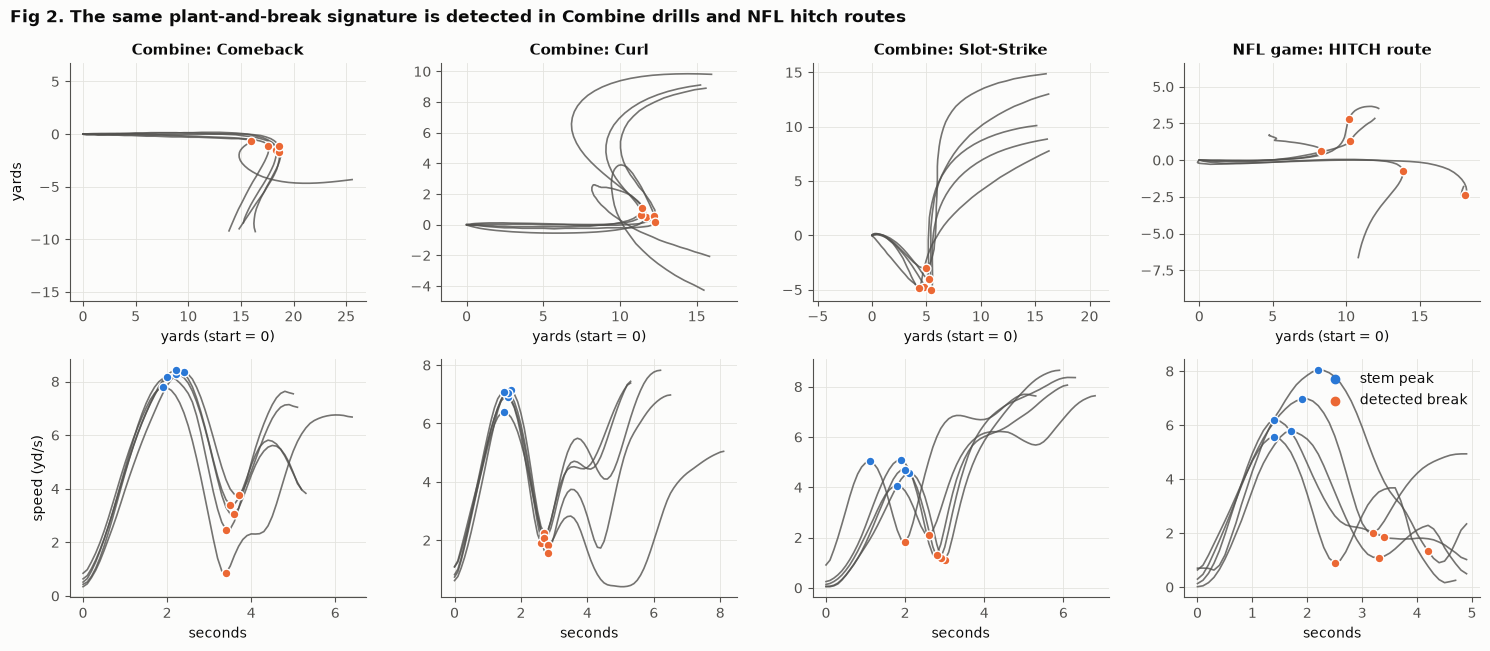

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.6))
rng = np.random.default_rng(SEED)
panels = [("COMEBACK_ROUTE_RIGHT", "Combine: Comeback"), ("CURL_ROUTE_RIGHT", "Combine: Curl"),
          ("SLOT_STRIKE_ROUTE_LEFT", "Combine: Slot-Strike"), ("HITCH", "NFL game: HITCH route")]
for col, (drill, title) in enumerate(panels):
    if drill == "HITCH":
        ok = groutes[(groutes.route_ran == "HITCH") & (groutes.break_found == 1)]
        picks = ok.sample(5, random_state=SEED)[TRK_KEY].itertuples(index=False)
        trajs = []
        for k in picks:
            g = gtr[(gtr.game_id == k.game_id) & (gtr.play_id == k.play_id) & (gtr.nfl_id == k.nfl_id)]
            i0 = np.flatnonzero(g.event.to_numpy() == "ball_snap")[0]
            g = g.iloc[i0:i0 + 50]; trajs.append(g)
        pk = 3.5
    else:
        sub = att[(att.drill_name == drill) & (att.break_found == 1)].sample(5, random_state=SEED)
        trajs = [ctw[(ctw.nfl_id == r.nfl_id) & (ctw.event_id == r.event_id) & (ctw.drill_name == drill)
                     & (ctw.attempt == r.attempt)] for r in sub.itertuples()]
        pk = 4.0
    for g in trajs:
        x, y, s = (g[c].to_numpy(float) for c in ("x", "y", "s"))
        b = break_features(x, y, s, min_peak=pk)
        x0, y0 = x - x[0], y - y[0]
        if drill == "HITCH":   # orient each game route so the stem runs along +x
            th = -np.arctan2(y0[b["i_peak"]], x0[b["i_peak"]]); c_, s_ = np.cos(th), np.sin(th)
            x0, y0 = x0 * c_ - y0 * s_, x0 * s_ + y0 * c_
        t = np.arange(len(s)) * DT; ss = smooth(s)
        axes[0, col].plot(x0, y0, color=INK2, lw=1.2, alpha=.8)
        axes[0, col].scatter(x0[b["i_break"]], y0[b["i_break"]], color=C2, s=40, zorder=3, edgecolor="white")
        axes[1, col].plot(t, ss, color=INK2, lw=1.2, alpha=.8)
        axes[1, col].scatter(t[b["i_peak"]], ss[b["i_peak"]], color=C1, s=40, zorder=3, edgecolor="white")
        axes[1, col].scatter(t[b["i_break"]], ss[b["i_break"]], color=C2, s=40, zorder=3, edgecolor="white")
    axes[0, col].set_title(title); axes[0, col].set_aspect("equal", adjustable="datalim")
    axes[0, col].set_xlabel("yards (start = 0)"); axes[1, col].set_xlabel("seconds")
axes[1, 0].set_ylabel("speed (yd/s)"); axes[0, 0].set_ylabel("yards")
axes[1, 3].scatter([], [], color=C1, label="stem peak"); axes[1, 3].scatter([], [], color=C2, label="detected break")
axes[1, 3].legend(frameon=False, loc="upper right")
fig.suptitle("Fig 2. The same plant-and-break signature is detected in Combine drills and NFL hitch routes", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "fig2_break_detection")

**Does the detector find real breaks?** Yes, in the drills where a break exists.
- **Detection rates:** the detector fires on 100% of Comeback, 95% of Curl and 98% of Slot-Strike Combine reps. The median heading change at the detected point is 71°, 87° and 129° respectively, consistent with the drill shapes in the top row of Fig 2.
- **NFL hitch routes** show the same signature: 56% detection, an 83° turn, and a median break speed of 1.1 yd/s.
- **Other routes:** detection is low on GO, POST and CORNER routes (≈10%), as it should be, because those routes have no planted break. Combine speed-cut drills such as Dagger and Speed-Out (not shown) were excluded for the same reason: their breaks are rounded, so a "break deceleration" label would be misleading.

Fig 2 plots five randomly sampled reps per panel. The blue point is the stem peak and the orange point the detected break; in every sampled trace the break sits at the visible planting point. This validates the *measurement procedure*. It does not yet show that the measurement is a stable *player trait*, which is tested next.

### 5.3 Player-level feature tables and reliability

In [12]:
# ---- Combine player features ------------------------------------------------------------------
hb = att[att.drill_name.isin(HARD_BREAK) & att.break_found.eq(1)]
hb_pd = hb.groupby(["nfl_id", "drill_name"])[["decel_rate", "reaccel_rate"]].mean()
hb_z = hb_pd.groupby("drill_name").transform(lambda v: (v - v.mean()) / v.std())
routes_att = att[att.drill_type.eq("SKILL_DRILLS_WR") & ~att.drill_name.isin(NON_ROUTE)]
cfeat = pd.DataFrame({
    "trk_break_decel": hb_z.decel_rate.groupby("nfl_id").mean(),
    "trk_break_reaccel": hb_z.reaccel_rate.groupby("nfl_id").mean(),
    "trk_hb_drills": hb_pd.groupby("nfl_id").size(),
    "trk_launch": routes_att.groupby("nfl_id").launch.mean(),
    "trk_top_speed": att[att.drill_name.isin(["GO_ROUTE_RIGHT", "FORTY_YARD_DASH"])].groupby("nfl_id").peak_speed.max(),
    "trk_route_peak_accel": routes_att[routes_att.drill_name.str.contains("ROUTE")].groupby("nfl_id").peak_accel.mean(),
})
cfeat["trk_break_index"] = cfeat[["trk_break_decel", "trk_break_reaccel"]].mean(axis=1)
# Legacy features from the earlier notebook (Dagger Route Left), recomputed for verification.
dag = att[att.drill_name.eq("DAGGER_ROUTE_LEFT")].groupby("nfl_id").peak_accel
cfeat["legacy_dagger_peak_accel"] = dag.mean(); cfeat["legacy_route_best_peak_accel"] = \
    routes_att[routes_att.drill_name.str.contains("ROUTE")].groupby("nfl_id").peak_accel.max()
cfeat.index.name = "nfl_id"

# ---- Game player features ---------------------------------------------------------------------
gfeat = pd.DataFrame({
    "g_hitch_decel": groutes[(groutes.route_ran == "HITCH") & (groutes.break_found == 1)].groupby("nfl_id").decel_rate.median(),
    "g_hitch_n": groutes[(groutes.route_ran == "HITCH") & (groutes.break_found == 1)].groupby("nfl_id").size(),
    "g_top_speed": groutes[groutes.route_ran == "GO"].groupby("nfl_id").route_peak_speed.quantile(0.9),
    "g_go_n": groutes[groutes.route_ran == "GO"].groupby("nfl_id").size(),
    "g_launch": groutes.groupby("nfl_id").launch.median(),
    "g_routes_n": groutes.groupby("nfl_id").size(),
})
gfeat.loc[gfeat.g_hitch_n.fillna(0) < 10, "g_hitch_decel"] = np.nan
gfeat.loc[gfeat.g_go_n.fillna(0) < 15, "g_top_speed"] = np.nan
gfeat.loc[gfeat.g_routes_n.fillna(0) < 30, "g_launch"] = np.nan
TRK = ["trk_break_index", "trk_break_decel", "trk_break_reaccel", "trk_launch", "trk_top_speed", "trk_route_peak_accel"]
display(cfeat[TRK + ["trk_hb_drills"]].describe().T)
display(gfeat.describe().T)
save_table(cfeat.reset_index(), "03_combine_tracking_player_features")
save_table(att, "04_combine_attempt_features")
save_table(gfeat.reset_index(), "05_game_tracking_player_features")

,count,mean,std,min,25%,50%,75%,max
trk_break_index,105.000,0.018,0.605,-2.072,-0.367,0.098,0.423,1.307
trk_break_decel,105.000,0.011,0.699,-2.061,-0.491,0.116,0.558,1.367
trk_break_reaccel,105.000,0.025,0.671,-2.084,-0.368,-0.017,0.458,1.771
trk_launch,106.000,4.025,0.273,3.171,3.900,4.042,4.198,4.747
trk_top_speed,105.000,10.985,0.453,9.251,10.857,11.060,11.298,11.812
trk_route_peak_accel,106.000,6.725,0.266,6.024,6.564,6.711,6.855,7.501
trk_hb_drills,105.000,2.829,0.448,1.000,3.000,3.000,3.000,3.000


,count,mean,std,min,25%,50%,75%,max
g_hitch_decel,59.000,3.428,0.304,2.727,3.210,3.412,3.670,4.033
g_hitch_n,75.000,42.000,40.470,1.000,11.000,29.000,59.500,174.000
g_top_speed,67.000,8.989,0.347,8.151,8.799,8.954,9.253,9.793
g_go_n,80.000,84.375,81.199,1.000,26.500,57.000,117.250,365.000
g_launch,73.000,4.519,0.271,3.490,4.369,4.547,4.667,5.320
g_routes_n,82.000,424.476,407.216,2.000,136.500,271.500,683.500,"1,522.000"


,nfl_id,g_hitch_decel,g_hitch_n,g_top_speed,g_go_n,g_launch,g_routes_n
0,55884,3.197,131.000,8.827,228.000,4.369,1522
1,55885,3.658,139.000,9.379,340.000,4.717,1315
2,55887,3.721,130.000,9.083,282.000,4.627,1481
3,55904,3.601,90.000,8.692,130.000,4.705,807
4,55915,3.064,67.000,9.340,100.000,4.537,848
...,...,...,...,...,...,...,...
77,58440,3.132,10.000,9.382,52.000,4.558,282
78,58447,2.772,11.000,8.780,31.000,4.316,168
79,58751,NaN,NaN,NaN,1.000,NaN,3
80,58968,NaN,NaN,NaN,1.000,NaN,20


In [13]:
# ---- Reliability: can a single Combine session measure a stable trait? ------------------------
def split_half(df, unit, value, seed=SEED):
    d = df.sample(frac=1, random_state=seed).copy()
    d["half"] = d.groupby(unit).cumcount() % 2
    w = d.groupby([unit, "half"])[value].mean().unstack().dropna()
    r = w.corr().iloc[0, 1]
    return len(w), r, 2 * r / (1 + r)     # Spearman-Brown corrected

rel = []
w = hb_z.decel_rate.unstack()
rel.append(("Combine break decel", "mean pairwise r between the 3 drills", int(w.dropna().shape[0]),
            np.nanmean([w.corr().values[i, j] for i in range(3) for j in range(i + 1, 3)]), np.nan))
w = hb_z.reaccel_rate.unstack()
rel.append(("Combine break re-accel", "mean pairwise r between the 3 drills", int(w.dropna().shape[0]),
            np.nanmean([w.corr().values[i, j] for i in range(3) for j in range(i + 1, 3)]), np.nan))
n, r, sb = split_half(routes_att.dropna(subset=["launch"]), "nfl_id", "launch"); rel.append(("Combine launch", "split-half over drills", n, r, sb))
ts = att[att.drill_name.isin(["GO_ROUTE_RIGHT", "FORTY_YARD_DASH"])].groupby(["nfl_id", "drill_name"]).peak_speed.max().unstack().dropna()
rel.append(("Combine top speed", "Go route vs 40-yd dash", len(ts), ts.corr().iloc[0, 1], np.nan))
hh = groutes[(groutes.route_ran == "HITCH") & groutes.break_found.eq(1) & groutes.nfl_id.isin(gfeat.index[gfeat.g_hitch_decel.notna()])]
n, r, sb = split_half(hh, "nfl_id", "decel_rate"); rel.append(("Game hitch decel", "split-half over plays", n, r, sb))
gg = groutes[(groutes.route_ran == "GO") & groutes.nfl_id.isin(gfeat.index[gfeat.g_top_speed.notna()])]
n, r, sb = split_half(gg, "nfl_id", "route_peak_speed"); rel.append(("Game GO-route peak speed", "split-half over plays", n, r, sb))
reliability = save_table(pd.DataFrame(rel, columns=["measure", "method", "n_players", "r", "spearman_brown"]), "06_reliability")
display(reliability)

,measure,method,n_players,r,spearman_brown
0,Combine break decel,mean pairwise r between the 3 drills,90,0.199,NaN
1,Combine break re-accel,mean pairwise r between the 3 drills,90,0.071,NaN
2,Combine launch,split-half over drills,106,0.062,0.117
3,Combine top speed,Go route vs 40-yd dash,85,0.452,NaN
4,Game hitch decel,split-half over plays,59,0.528,0.692
5,Game GO-route peak speed,split-half over plays,67,0.752,0.858


**This is the pivotal diagnostic of the study.**
- **Break traits are unreliable at the Combine.** A WR's break deceleration in one drill barely predicts it in another: the mean pairwise r across the three hard-break drills is 0.20 for deceleration and 0.07 for re-acceleration. Launch acceleration across route drills has a split-half r of 0.06. Players run each drill about once (1.0–1.2 attempts per WR), so these metrics carry a lot of rep-specific noise: the footing, the throw and the drill script all vary.
- **Top speed is more reliable.** Go-route and 40-yd peak speeds agree at r = 0.45.
- **Game traits are reliable because there are many reps.** Hitch-break deceleration has a Spearman-Brown reliability of 0.69 and GO-route peak speed 0.86.

**Implication:** low reliability caps how strongly a Combine break metric *can* correlate with anything. This should be kept in mind when reading every null result below.

## 6. Regular-season target: Separation Over Expected (SOE)

**Definition from the data.** `separation_at_pass_forward` (yards) is populated on every route a
cohort WR ran on a pass play (target or not; verified in §3). Its distribution varies strongly by
route (screens and flats are open by design; go routes are tight), coverage, and cushion, so the raw
average mostly measures *role*, not ability.

**Construction.**
1. Rows: cohort WR, regular season, `route_ran` recorded, separation not missing, not nullified.
2. Context model (OLS, play level): `separation ~ route × coverage type + cushion + cushion² + cushion-missing + alignment (WR / slot / other) + down + yards-to-go + season + offensive formation`.
   Targeting is **not** adjusted for: QBs throw to open receivers, so it is a consequence of separation.
3. Each player's mean residual is shrunk toward 0 with a random-intercept model
   (`resid ~ 1 + (1 | player)`), giving a best linear unbiased predictor (**SOE**, yards per route).
   The shrinkage handles players with few routes.
4. ML and correlation analyses use players with ≥ `MIN_ROUTES` = 50 routes; the weighted
   regression uses precision weights 1/(τ² + σ²/n) instead of a hard cut-off.

SOE is still **not** a pure talent measure: QB timing, play design and teammates are not fully
controlled, and the context model is fitted on all cohort plays (outcome construction, not predictors).

In [14]:
MIN_ROUTES = 50
sep = reg_routes[reg_routes.separation_at_pass_forward.notna() & reg_routes.play_nullified_by_penalty.ne("Y")].copy()
sep["align"] = sep.lined_up_position.where(sep.lined_up_position.isin(["WR", "SLOT_WR"]), "OTHER")
sep["cov"] = sep.team_coverage_type.fillna("UNKNOWN")
sep["cush_miss"] = sep.cushion.isna().astype(int)
sep["cush"] = sep.cushion.clip(0, 20).fillna(sep.cushion.median())
sep["ytg"] = sep.yards_to_go.clip(1, 20); sep["down"] = sep.down.clip(1, 4)
sep["formation"] = sep.offense_formation.fillna("UNKNOWN")
CTX = ("separation_at_pass_forward ~ C(route_ran)*C(cov) + cush + I(cush**2) + cush_miss + C(align)"
       " + C(down) + ytg + C(season) + C(formation)")
ctx_fit = smf.ols(CTX, data=sep).fit()
sep["resid"] = ctx_fit.resid
re_fit = smf.mixedlm("resid ~ 1", sep, groups=sep["nfl_id"]).fit(reml=True)
TAU2, SIG2 = float(re_fit.cov_re.iloc[0, 0]), float(re_fit.scale)
soe = sep.groupby("nfl_id").agg(routes=("resid", "size"), raw_sep=("separation_at_pass_forward", "mean"),
                                resid_mean=("resid", "mean"), targets=("target", "sum"),
                                slot_share=("align", lambda v: (v == "SLOT_WR").mean()))
soe["soe"] = pd.Series({k: v.iloc[0] for k, v in re_fit.random_effects.items()})
soe["precision_w"] = 1 / (TAU2 + SIG2 / soe.routes)
soe["reliability"] = TAU2 / (TAU2 + SIG2 / soe.routes)
n, r, sb = split_half(sep[sep.nfl_id.isin(soe.index[soe.routes >= MIN_ROUTES])], "nfl_id", "resid")
KEY.update(sep_rows=len(sep), sep_players=int(soe.shape[0]), soe_players_min=int((soe.routes >= MIN_ROUTES).sum()),
           ctx_r2=ctx_fit.rsquared, tau=np.sqrt(TAU2), sigma=np.sqrt(SIG2), soe_split_half=r, soe_sb=sb,
           median_routes=float(soe.routes.median()))
print(f"Plays: {len(sep):,} | WRs: {soe.shape[0]} | WRs with >= {MIN_ROUTES} routes: {KEY['soe_players_min']}")
print(f"Context model R2 = {ctx_fit.rsquared:.3f};  between-player SD tau = {np.sqrt(TAU2):.3f} yd;  "
      f"within SD = {np.sqrt(SIG2):.2f} yd")
print(f"Split-half reliability of player residual means (>= {MIN_ROUTES} routes): r = {r:.2f} (Spearman-Brown {sb:.2f})")
display(soe.describe().T)
print("Raw separation vs SOE (players >= MIN_ROUTES):",
      soe[soe.routes >= MIN_ROUTES][["raw_sep", "soe", "slot_share"]].corr().round(2).to_dict())

/tmp/ipykernel_3597907/2814007316.py:11: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ctx_fit = smf.ols(CTX, data=sep).fit()


Plays: 30,566 | WRs: 82 | WRs with >= 50 routes: 68
Context model R2 = 0.275;  between-player SD tau = 0.168 yd;  within SD = 1.79 yd
Split-half reliability of player residual means (>= 50 routes): r = 0.54 (Spearman-Brown 0.71)


,count,mean,std,min,25%,50%,75%,max
routes,82.000,372.756,359.237,2.000,120.500,249.000,590.250,"1,365.000"
raw_sep,82.000,3.111,0.455,1.461,2.862,3.062,3.330,5.039
resid_mean,82.000,0.002,0.287,-1.570,-0.139,0.009,0.175,1.011
targets,82.000,78.451,89.819,0.000,15.000,40.500,119.750,432.000
slot_share,82.000,0.335,0.180,0.000,0.208,0.306,0.465,0.737
soe,82.000,-0.000,0.132,-0.274,-0.091,-0.003,0.085,0.586
precision_w,82.000,21.683,9.211,0.612,18.181,24.245,29.590,32.574
reliability,82.000,0.615,0.261,0.017,0.515,0.687,0.839,0.923


Raw separation vs SOE (players >= MIN_ROUTES): {'raw_sep': {'raw_sep': 1.0, 'soe': 0.84, 'slot_share': 0.41}, 'soe': {'raw_sep': 0.84, 'soe': 1.0, 'slot_share': 0.1}, 'slot_share': {'raw_sep': 0.41, 'soe': 0.1, 'slot_share': 1.0}}


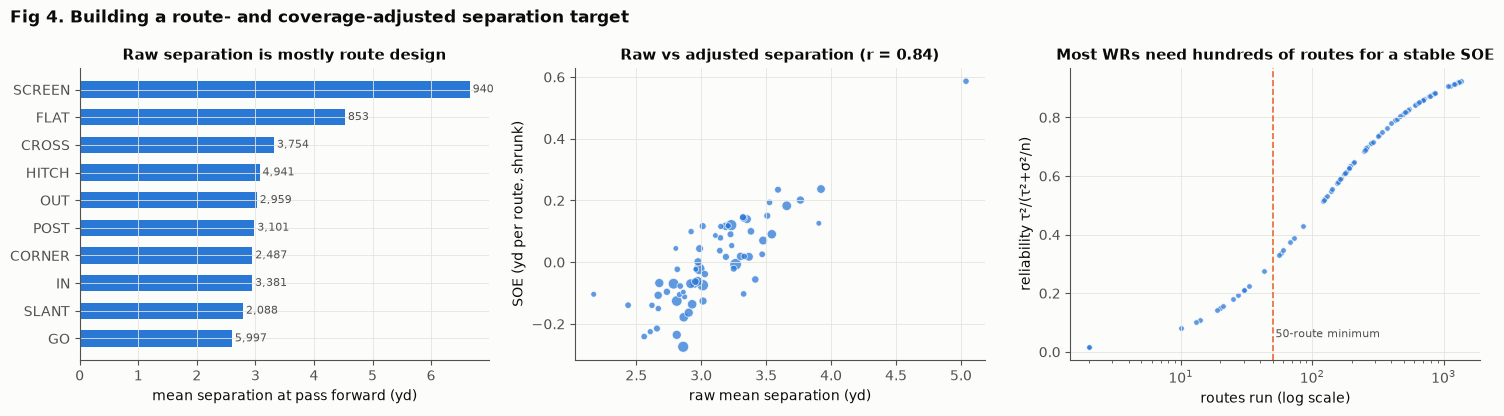

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
rt = sep.groupby("route_ran").separation_at_pass_forward.agg(["mean", "size"]).query("size >= 100").sort_values("mean")
ax[0].barh(rt.index, rt["mean"], color=C1, height=0.6)
ax[0].set_xlabel("mean separation at pass forward (yd)"); ax[0].set_title("Raw separation is mostly route design")
for i, (m_, n_) in enumerate(zip(rt["mean"], rt["size"])):
    ax[0].text(m_ + 0.05, i, f"{n_:,}", va="center", fontsize=8, color=INK2)
s50 = soe[soe.routes >= MIN_ROUTES]
ax[1].scatter(s50.raw_sep, s50.soe, s=14 + s50.routes / 25, color=C1, alpha=.75, edgecolor="white", lw=.6)
ax[1].set_xlabel("raw mean separation (yd)"); ax[1].set_ylabel("SOE (yd per route, shrunk)")
ax[1].set_title(f"Raw vs adjusted separation (r = {s50[['raw_sep','soe']].corr().iloc[0,1]:.2f})")
ax[2].scatter(soe.routes, soe.reliability, color=C1, s=16, alpha=.75, edgecolor="white", lw=.6)
ax[2].axvline(MIN_ROUTES, color=C2, lw=1.2, ls="--"); ax[2].text(MIN_ROUTES * 1.05, 0.05, f"{MIN_ROUTES}-route minimum", color=INK2, fontsize=8)
ax[2].set_xscale("log"); ax[2].set_xlabel("routes run (log scale)"); ax[2].set_ylabel("reliability τ²/(τ²+σ²/n)")
ax[2].set_title("Most WRs need hundreds of routes for a stable SOE")
fig.suptitle("Fig 4. Building a route- and coverage-adjusted separation target", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "fig4_soe_construction")

In [16]:
# ---- SOE sign and meaning check ---------------------------------------------------------------
# SOE = player's shrunk mean of (observed separation - context-expected separation).
# Positive SOE => the WR is more open than the route/coverage/cushion context predicts.
s50 = soe[soe.routes >= MIN_ROUTES].copy()
s50["soe_q"] = pd.qcut(s50.soe, 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
chk = sep[sep.nfl_id.isin(s50.index)].assign(soe_q=lambda d: d.nfl_id.map(s50.soe_q))
big = chk.route_ran.value_counts(); big = big[big >= 1000].index
by_route = chk[chk.route_ran.isin(big)].pivot_table(index="route_ran", columns="soe_q", values="separation_at_pass_forward",
                                                    aggfunc="mean", observed=True)
by_route["Q4 minus Q1 (yd)"] = by_route["Q4 highest"] - by_route["Q1 lowest"]
display(by_route.round(2))
rec = sep.assign(rec_yards=sep.rec_yards.fillna(0)).groupby("nfl_id").agg(tgt_per_route=("target", "mean"), yds_per_route=("rec_yards", "mean"))
val = s50.join(rec).groupby("soe_q", observed=True).agg(WRs=("soe", "size"), mean_soe=("soe", "mean"), raw_sep=("raw_sep", "mean"),
                                                        targets_per_route=("tgt_per_route", "mean"), rec_yds_per_route=("yds_per_route", "mean"))
display(save_table(val.reset_index(), "20_soe_direction_check"))
r_t = stats.spearmanr(s50.soe, s50.join(rec).tgt_per_route); r_y = stats.spearmanr(s50.soe, s50.join(rec).yds_per_route)
KEY.update(soe_q4_minus_q1_routes_positive=int((by_route["Q4 minus Q1 (yd)"] > 0).sum()), soe_n_routes_checked=len(by_route),
           soe_rho_tgt=r_t[0], soe_p_tgt=r_t[1], soe_rho_yds=r_y[0], soe_p_yds=r_y[1])
print(f"Q4 > Q1 separation on {KEY['soe_q4_minus_q1_routes_positive']} of {len(by_route)} common route types.")
print(f"SOE vs targets per route: Spearman rho = {r_t[0]:.2f} (p = {r_t[1]:.3f}); vs receiving yards per route: rho = {r_y[0]:.2f} (p = {r_y[1]:.3f})")

soe_q,Q1 lowest,Q2,Q3,Q4 highest,Q4 minus Q1 (yd)
route_ran,,,,,
CORNER,2.830,2.860,3.040,3.150,0.320
CROSS,2.940,3.150,3.360,3.870,0.930
GO,2.370,2.450,2.700,2.910,0.540
HITCH,2.870,3.000,3.100,3.420,0.540
IN,2.680,2.920,3.170,3.190,0.510
OUT,2.770,3.010,3.240,3.080,0.310
POST,2.860,2.880,3.130,3.090,0.230
SLANT,2.620,2.770,2.790,3.020,0.400


,soe_q,WRs,mean_soe,raw_sep,targets_per_route,rec_yds_per_route
0,Q1 lowest,17,-0.163,2.724,0.183,1.246
1,Q2,17,-0.061,2.970,0.193,1.529
2,Q3,17,0.046,3.206,0.209,1.673
3,Q4 highest,17,0.178,3.535,0.186,1.371


Q4 > Q1 separation on 8 of 8 common route types.
SOE vs targets per route: Spearman rho = 0.09 (p = 0.450); vs receiving yards per route: rho = 0.13 (p = 0.309)


**Target interpretation (Fig 4).**
- **Sample:** 30,566 regular-season routes by 82 WRs; 68 WRs have at least 50 routes.
- **Context matters:** the context model explains 27.5% of play-level separation. The left panel shows why raw separation is mostly *role*: screens average 6.7 yards and go routes 2.6.
- **The player signal is real but small.** Between-player SD of SOE (τ) is 0.17 yards per route, against a within-player SD of 1.79. Split-half reliability is still respectable for WRs with at least 50 routes (r = 0.54, Spearman-Brown 0.71).
- **Raw separation and SOE agree only partly** (r = 0.84). Raw separation correlates 0.41 with slot share, while SOE correlates only 0.10, so the adjustment removes much of the alignment effect.
- **Exposure:** the right panel shows that a typical 2025 rookie (median 162 routes) has reliability around 0.6. Weighting by precision is therefore essential.

**SOE direction check (verified above).**
- **Positive SOE means more open than the context predicts**, in yards per route. Sorting WRs into SOE quartiles, the top quartile is more open than the bottom quartile on **8 of 8** common route types, by 0.23–0.93 yards on the *same* route. So the sign and units behave as intended within route type.
- **SOE is not production.** SOE is essentially unrelated to targets per route (ρ = 0.09, p = 0.45) and receiving yards per route (ρ = 0.13, p = 0.31) in this sample. Being open at the moment of the throw is only one input to production: QB reads, play design, catch skill and yards after catch matter too. SOE should be read as a measure of *getting open*, not of overall receiver value.

## 7. Master table, cohort characteristics and exploratory analysis

In [17]:
TRAD = ["combine_height", "combine_weight", "forty", "ten_yd_split", "vertical", "broad_jump"]
master = (wr[["nfl_id", "display_name", "draft_year", "draft_round", "draft_overall_pick", "college_conference"]
             + TRAD + ["three_cone", "short_shuttle", "ngs_athleticism_score"]]
          .merge(cfeat.reset_index(), on="nfl_id", how="left", validate="one_to_one")
          .merge(gfeat.reset_index(), on="nfl_id", how="left", validate="one_to_one")
          .merge(soe.reset_index(), on="nfl_id", how="left", validate="one_to_one")
          .merge(career, on="nfl_id", how="left", validate="one_to_one"))
master["drafted"] = master.draft_overall_pick.notna().astype(int)
master["pick_filled"] = master.draft_overall_pick.fillna(master.draft_overall_pick.max() + 1)
assert master.nfl_id.is_unique
save_table(master, "07_wr_master_table")

attr = pd.DataFrame([
    ("Prospects in players.csv (all positions)", len(players)),
    ("NFL-listed WRs drafted/signed 2023-25", len(wr)),
    ("  ...with Combine tracking frames", ctw.nfl_id.nunique()),
    ("  ...with >=1 detected hard-break drill (break_index)", int(master.trk_break_index.notna().sum())),
    ("  ...with any player_play row", ppw.nfl_id.nunique()),
    ("  ...with REG-season routes + separation", int(master.routes.notna().sum())),
    (f"  ...with >= {MIN_ROUTES} REG routes (SOE analysis set)", int((master.routes >= MIN_ROUTES).sum())),
    ("  ...and break_index + 40/10/jumps/size complete (primary regression)",
     int(master[(master.routes >= MIN_ROUTES)].dropna(subset=["trk_break_index"] + TRAD).shape[0])),
    ("  ...with game hitch-break decel (>=10 detected hitches)", int(master.g_hitch_decel.notna().sum())),
], columns=["stage", "unique WRs"])
save_table(attr, "08_attrition"); display(attr)
KEY["attrition"] = attr.set_index("stage")["unique WRs"].to_dict()

,stage,unique WRs
0,Prospects in players.csv (all positions),510
1,NFL-listed WRs drafted/signed 2023-25,106
2,...with Combine tracking frames,106
3,...with >=1 detected hard-break drill (break...,105
4,...with any player_play row,105
5,...with REG-season routes + separation,82
6,...with >= 50 REG routes (SOE analysis set),68
7,...and break_index + 40/10/jumps/size comple...,56
8,...with game hitch-break decel (>=10 detecte...,59


In [18]:
# Cohort coverage by draft class: exposure differs by construction (2025 class has one season).
cov_tab = master.groupby("draft_year").agg(
    WRs=("nfl_id", "size"), drafted=("drafted", "sum"), with_tracking=("trk_top_speed", "count"),
    with_REG_routes=("routes", "count"), ge50_routes=("routes", lambda v: (v >= MIN_ROUTES).sum()),
    median_routes=("routes", "median"), median_career_snaps=("career_offensive_snaps", "median"))
display(cov_tab)
unmatched = master[master.routes.isna()]
print(f"{len(unmatched)} WRs have no REG separation rows. Draft status of these players:",
      unmatched.drafted.value_counts().rename({1: "drafted", 0: "undrafted"}).to_dict(),
      "| median career offensive snaps:", unmatched.career_offensive_snaps.median())
drills_pp = att.groupby("drill_name").agg(WRs=("nfl_id", "nunique"), attempts=("nfl_id", "size"))
drills_pp["attempts_per_WR"] = drills_pp.attempts / drills_pp.WRs
display(drills_pp.sort_values("WRs", ascending=False).T)

,WRs,drafted,with_tracking,with_REG_routes,ge50_routes,median_routes,median_career_snaps
draft_year,,,,,,,
2023,38,26,37,31,28,604.000,687.000
2024,31,27,31,28,23,228.500,367.000
2025,37,23,37,23,17,162.000,58.000


24 WRs have no REG separation rows. Draft status of these players: {'undrafted': 20, 'drafted': 4} | median career offensive snaps: 0.0


drill_name,DAGGER_ROUTE_LEFT,SPEED_OUT_ROUTE_LEFT,GAUNTLET_DRILL,SLANT_ROUTE_LEFT,CURL_ROUTE_RIGHT,SLOT_STRIKE_ROUTE_LEFT,OVER_SHOULDER_ADJUST,SLOT_SAIL_ROUTE_RIGHT,GO_ROUTE_RIGHT,COMEBACK_ROUTE_RIGHT,RED_ZONE_FADE_RIGHT,POST_CORNER_ROUTE_RIGHT,FORTY_YARD_DASH,POST_CORNER_ROUTE_LEFT,CIRCUS_ROUTE_LEFT,SHORT_SHUTTLE,THREE_CONE_DRILL
WRs,106.000,106.000,106.000,106.000,102.000,100.000,99.000,97.000,97.000,97.000,97.000,95.000,93.000,69.000,37.000,29.000,24.000
attempts,114.000,123.000,198.000,109.000,109.000,101.000,100.000,104.000,104.000,109.000,110.000,110.000,174.000,79.000,43.000,36.000,30.000
attempts_per_WR,1.075,1.160,1.868,1.028,1.069,1.010,1.010,1.072,1.072,1.124,1.134,1.158,1.871,1.145,1.162,1.241,1.250


In [19]:
# Survivorship check: do WRs who reach the SOE analysis set differ at the Combine?
in_set = master.routes >= MIN_ROUTES
surv = []
for c in TRAD + ["trk_break_index", "trk_top_speed", "trk_launch", "pick_filled"]:
    a_, b_ = master.loc[in_set, c].dropna(), master.loc[~in_set, c].dropna()
    surv.append({"feature": c, "mean_in_set": a_.mean(), "mean_excluded": b_.mean(), "n_in": len(a_), "n_out": len(b_),
                 "mann_whitney_p": stats.mannwhitneyu(a_, b_).pvalue})
display(save_table(pd.DataFrame(surv), "09_survivorship_check"))

,feature,mean_in_set,mean_excluded,n_in,n_out,mann_whitney_p
0,combine_height,72.564,73.112,68,38,0.156
1,combine_weight,195.588,199.000,68,38,0.278
2,forty,4.458,4.497,63,33,0.054
3,ten_yd_split,1.531,1.538,63,33,0.097
4,vertical,37.658,34.829,60,35,0.000
5,broad_jump,126.574,123.152,61,33,0.000
6,trk_break_index,0.007,0.038,67,38,0.537
7,trk_top_speed,11.058,10.855,67,38,0.039
8,trk_launch,4.012,4.050,68,38,0.596
9,pick_filled,129.662,229.737,68,38,0.000


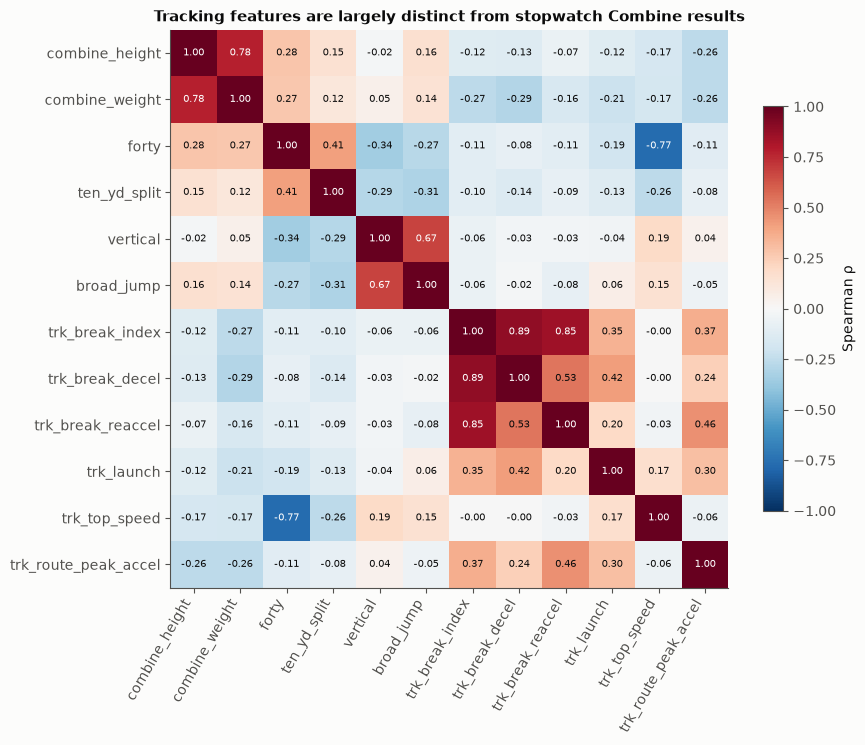

In [20]:
# Correlation structure among traditional and tracking features (WR cohort).
cm_cols = TRAD + ["trk_break_index", "trk_break_decel", "trk_break_reaccel", "trk_launch", "trk_top_speed", "trk_route_peak_accel"]
corrm = master[cm_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corrm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm_cols))); ax.set_xticklabels(cm_cols, rotation=60, ha="right"); ax.set_yticks(range(len(cm_cols))); ax.set_yticklabels(cm_cols)
for i in range(len(cm_cols)):
    for j in range(len(cm_cols)):
        ax.text(j, i, f"{corrm.iat[i,j]:.2f}", ha="center", va="center", fontsize=7, color=INK if abs(corrm.iat[i, j]) < .6 else "white")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=.7, label="Spearman ρ")
ax.set_title("Tracking features are largely distinct from stopwatch Combine results"); savefig(fig, "diag_feature_correlations")

**Cohort and survivorship.**
- **Attrition:** 106 WRs → 105 with a break index → 82 with regular-season separation → 68 with at least 50 routes → 56 with a complete primary-model row (missing 40/jumps account for the last drop).
- **Who is missing:** of the 24 WRs with no regular-season routes, 20 were undrafted, and their median career offensive snaps is 0.
- **Survivorship is real and selective.** WRs who reached the SOE set jumped higher (vertical 37.7 vs 34.8 in, p < 0.001), were drafted much earlier (mean pick 130 vs 230), and had faster tracked top speed (11.06 vs 10.86 yd/s, p = 0.04). They did **not** differ on the break index (p = 0.54). Any SOE analysis is therefore conditional on making an NFL roster; it cannot say whether break mechanics help players *get* on the field.
- **Feature overlap (diagnostic heatmap):** the break, launch and route-acceleration features are nearly unrelated to stopwatch results (|ρ| ≤ 0.29), so they *could* carry new information. Tracked top speed is strongly but not perfectly related to the 40 (ρ = −0.77).

## 8. Do Combine movement traits show up in NFL games? (Combine tracking → game tracking)

Before asking whether a Combine trait predicts an *outcome*, we ask whether it measures the same
movement in games. Top speed is the **positive control**: if Combine tracking cannot reproduce
game top speed, nothing subtler will work. Each Combine trait is paired with its game analogue,
measured on the same players in regular-season tracking.

In [21]:
def boot_corr(x, y, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed); x, y = np.asarray(x), np.asarray(y); n = len(x)
    bs = [np.corrcoef(x[i], y[i])[0, 1] for i in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(bs, [2.5, 97.5])

pairs = [("trk_top_speed", "g_top_speed", "Top speed (positive control)"),
         ("forty", "g_top_speed", "40-yd time vs game top speed"),
         ("trk_launch", "g_launch", "Launch acceleration"),
         ("trk_break_decel", "g_hitch_decel", "Break deceleration"),
         ("trk_break_index", "g_hitch_decel", "Break index vs game hitch decel")]
tr = []
for a_, b_, lab in pairs:
    d = master[[a_, b_]].dropna()
    r, p = stats.pearsonr(d[a_], d[b_]); lo, hi = boot_corr(d[a_], d[b_])
    tr.append({"comparison": lab, "combine": a_, "game": b_, "n": len(d), "pearson_r": r, "ci_low": lo, "ci_high": hi,
               "p": p, "spearman_rho": stats.spearmanr(d[a_], d[b_])[0]})
translation = save_table(pd.DataFrame(tr), "10_translation_combine_to_game")
display(translation)
# Does tracked top speed add to the stopwatch 40 for predicting game top speed?
d = master[["g_top_speed", "trk_top_speed", "forty"]].dropna()
m1 = smf.ols("g_top_speed ~ forty", d).fit(); m2 = smf.ols("g_top_speed ~ forty + trk_top_speed", d).fit(cov_type="HC3")
print(f"n={len(d)}  R2 forty only = {m1.rsquared:.3f};  + tracked top speed = {m2.rsquared:.3f};  "
      f"trk_top_speed coef = {m2.params['trk_top_speed']:.3f} (95% CI {m2.conf_int().loc['trk_top_speed'][0]:.3f}"
      f" to {m2.conf_int().loc['trk_top_speed'][1]:.3f}), p = {m2.pvalues['trk_top_speed']:.4f}")
KEY.update(top_r2_forty=m1.rsquared, top_r2_both=m2.rsquared, top_n=len(d), top_coef=m2.params["trk_top_speed"],
           top_p=m2.pvalues["trk_top_speed"], translation=translation.set_index("comparison")[["n", "pearson_r", "ci_low", "ci_high", "p"]].round(4).to_dict("index"))

,comparison,combine,game,n,pearson_r,ci_low,ci_high,p,spearman_rho
0,Top speed (positive control),trk_top_speed,g_top_speed,66,0.478,0.262,0.642,0.000,0.481
1,40-yd time vs game top speed,forty,g_top_speed,62,-0.360,-0.573,-0.109,0.004,-0.409
2,Launch acceleration,trk_launch,g_launch,73,-0.010,-0.195,0.188,0.936,-0.067
3,Break deceleration,trk_break_decel,g_hitch_decel,58,0.007,-0.297,0.315,0.960,0.047
4,Break index vs game hitch decel,trk_break_index,g_hitch_decel,58,-0.102,-0.352,0.173,0.446,-0.023


n=62  R2 forty only = 0.129;  + tracked top speed = 0.213;  trk_top_speed coef = 0.550 (95% CI -0.090 to 1.190), p = 0.0919


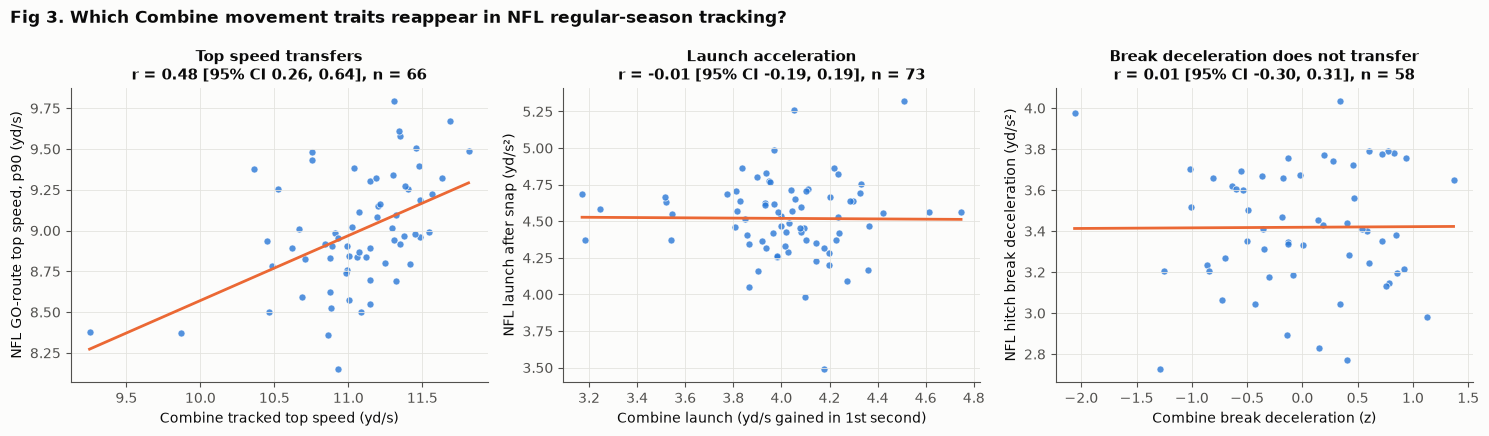

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
specs = [("trk_top_speed", "g_top_speed", "Combine tracked top speed (yd/s)", "NFL GO-route top speed, p90 (yd/s)", "Top speed transfers"),
         ("trk_launch", "g_launch", "Combine launch (yd/s gained in 1st second)", "NFL launch after snap (yd/s²)", "Launch acceleration"),
         ("trk_break_decel", "g_hitch_decel", "Combine break deceleration (z)", "NFL hitch break deceleration (yd/s²)", "Break deceleration does not transfer")]
for ax, (a_, b_, xl, yl, tt) in zip(axes, specs):
    d = master[[a_, b_]].dropna(); row = translation[(translation["combine"] == a_) & (translation["game"] == b_)].iloc[0]
    ax.scatter(d[a_], d[b_], color=C1, s=26, alpha=.8, edgecolor="white", lw=.6)
    b1, b0 = np.polyfit(d[a_], d[b_], 1); xs = np.linspace(d[a_].min(), d[a_].max(), 50)
    ax.plot(xs, b0 + b1 * xs, color=C2, lw=2)
    ax.set_title(f"{tt}\nr = {row.pearson_r:.2f} [95% CI {row.ci_low:.2f}, {row.ci_high:.2f}], n = {row.n}")
    ax.set_xlabel(xl); ax.set_ylabel(yl)
fig.suptitle("Fig 3. Which Combine movement traits reappear in NFL regular-season tracking?", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "fig3_translation")

**Combine → game transfer (Fig 3).**
- **Positive control passes.** Combine-tracked top speed correlates r = 0.48 (95% CI 0.26–0.64, n = 66) with the 90th-percentile speed a WR reaches on NFL GO routes. The official 40 time correlates −0.36 (CI −0.57 to −0.11, n = 62). Adding tracked top speed to the 40 raises explained variance in game top speed from 12.9% to 21.3%, although that coefficient on its own is imprecise (p = 0.09, HC3).
- **Launch acceleration does not transfer** (r = −0.01).
- **Break deceleration does not transfer** (r = 0.01, CI −0.30 to 0.31, n = 58), and neither does the composite break index (r = −0.10).
- **Why:** the most likely explanation is the measurement ceiling identified above. A metric that does not agree with itself across Combine drills cannot agree with a game metric. A second explanation is also plausible: NFL hitch breaks are timed to the quarterback and the defender, whereas Combine breaks are scripted.

**What this does not show:** it does not show that break skill is unimportant in the NFL. It shows that a single Combine session does not measure break skill well enough to detect it.

## 9. Statistical analysis

**Primary hypothesis (fixed before any separation model was fitted):**
- **H0:** the Combine break index has no association with SOE after adjusting for height, weight, 40, 10-yd split, vertical, broad jump and draft year.
- **H1:** a higher break index (faster deceleration into and re-acceleration out of planted breaks) is associated with higher SOE.

**Model:** weighted least squares at the player level. The outcome is each WR's mean context-model residual, with precision weights 1/(τ² + σ²/n_routes). Inference uses HC3 robust standard errors, with a 2,000-replicate player-bootstrap CI as a check. Predictors are standardised, so coefficients read as *yards of separation per route per 1 SD of the feature*.

**Secondary family (8 tests, Benjamini–Hochberg FDR):** each break component, launch, tracked top speed, the earlier notebook's route peak acceleration, and the three game-tracking analogues, each in the same adjusted model.

In [23]:
def zs(s): return (s - s.mean()) / s.std()
ana = master[master.routes >= MIN_ROUTES].copy()
FEATS_ALL = TRK + ["g_hitch_decel", "g_top_speed", "g_launch"] + TRAD
for c in FEATS_ALL: ana[c + "_z"] = zs(ana[c])
ADJ = " + ".join(c + "_z" for c in TRAD) + " + C(draft_year)"

# ---- Descriptive, unadjusted -------------------------------------------------------------------
desc = []
for c in TRK + ["g_hitch_decel", "g_top_speed", "g_launch"] + TRAD:
    d = ana[[c, "soe"]].dropna()
    desc.append({"feature": c, "n": len(d), "pearson_r": stats.pearsonr(d[c], d.soe)[0], "pearson_p": stats.pearsonr(d[c], d.soe)[1],
                 "spearman_rho": stats.spearmanr(d[c], d.soe)[0], "spearman_p": stats.spearmanr(d[c], d.soe)[1]})
display(save_table(pd.DataFrame(desc), "11_unadjusted_correlations_soe"))

,feature,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,trk_break_index,67,-0.138,0.266,-0.021,0.867
1,trk_break_decel,67,-0.067,0.591,0.020,0.873
2,trk_break_reaccel,67,-0.173,0.161,-0.092,0.457
3,trk_launch,68,0.133,0.281,0.222,0.069
4,trk_top_speed,67,0.269,0.028,0.267,0.029
5,trk_route_peak_accel,68,0.045,0.715,0.079,0.524
6,g_hitch_decel,59,-0.172,0.192,-0.195,0.139
7,g_top_speed,67,0.376,0.002,0.363,0.003
8,g_launch,68,-0.142,0.248,0.066,0.593
9,combine_height,68,-0.531,0.000,-0.476,0.000


In [24]:
# ---- Primary model: precision-weighted least squares, HC3 SEs, + player bootstrap -------------
def fit_feature(feat, data=ana, adjust=ADJ, outcome="resid_mean", weights="precision_w"):
    cols = [feat + "_z", outcome, weights, "draft_year"] + [c + "_z" for c in TRAD]
    d = data[cols].dropna()
    f = smf.wls(f"{outcome} ~ {feat}_z + {adjust}", d, weights=d[weights]).fit(cov_type="HC3")
    return f, d

prim, dprim = fit_feature("trk_break_index")
rng = np.random.default_rng(SEED); boots = []
for _ in range(2000):
    db = dprim.iloc[rng.integers(0, len(dprim), len(dprim))]
    try:
        boots.append(smf.wls(f"resid_mean ~ trk_break_index_z + {ADJ}", db, weights=db.precision_w).fit().params["trk_break_index_z"])
    except Exception:
        pass
b_lo, b_hi = np.percentile(boots, [2.5, 97.5])
base_only = smf.wls(f"resid_mean ~ {ADJ}", dprim, weights=dprim.precision_w).fit()
print(prim.summary().tables[1])
KEY.update(prim_n=int(prim.nobs), prim_coef=prim.params["trk_break_index_z"], prim_lo=prim.conf_int().loc["trk_break_index_z"][0],
           prim_hi=prim.conf_int().loc["trk_break_index_z"][1], prim_p=prim.pvalues["trk_break_index_z"],
           prim_boot_lo=b_lo, prim_boot_hi=b_hi, prim_dr2=prim.rsquared - base_only.rsquared)
print(f"\nPRIMARY: break_index (per 1 SD) -> SOE: {KEY['prim_coef']:+.3f} yd/route, 95% CI [{KEY['prim_lo']:+.3f}, {KEY['prim_hi']:+.3f}] "
      f"(HC3), player-bootstrap CI [{b_lo:+.3f}, {b_hi:+.3f}], p = {KEY['prim_p']:.3f}, n = {KEY['prim_n']}, "
      f"incremental weighted R2 = {KEY['prim_dr2']:.3f}")

                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.0145      0.035      0.411      0.681      -0.055       0.084
C(draft_year)[T.2024]    -0.0078      0.060     -0.129      0.897      -0.126       0.111
C(draft_year)[T.2025]     0.0309      0.061      0.504      0.614      -0.089       0.151
trk_break_index_z        -0.0344      0.020     -1.728      0.084      -0.073       0.005
combine_height_z         -0.0013      0.039     -0.034      0.972      -0.078       0.075
combine_weight_z         -0.0991      0.031     -3.223      0.001      -0.159      -0.039
forty_z                7.786e-05      0.027      0.003      0.998      -0.052       0.052
ten_yd_split_z           -0.0168      0.021     -0.804      0.422      -0.058       0.024
vertical_z               -0.0003      0.029     -0.010      0.992      -0.056       0.056
broad_jump

In [25]:
# ---- Secondary family (pre-listed): each feature in the same adjusted model, BH-FDR -----------
SECONDARY = ["trk_break_decel", "trk_break_reaccel", "trk_launch", "trk_top_speed", "trk_route_peak_accel",
             "g_hitch_decel", "g_top_speed", "g_launch"]
rows = []
for feat in ["trk_break_index"] + SECONDARY:
    f, d = fit_feature(feat)
    ci = f.conf_int().loc[feat + "_z"]
    rows.append({"feature": feat, "family": "primary" if feat == "trk_break_index" else "secondary",
                 "source": "Combine tracking" if feat.startswith("trk") else "Game tracking",
                 "n": int(f.nobs), "coef_yd_per_SD": f.params[feat + "_z"], "ci_low": ci[0], "ci_high": ci[1], "p": f.pvalues[feat + "_z"]})
assoc = pd.DataFrame(rows)
sec = assoc.family.eq("secondary")
assoc.loc[sec, "p_BH"] = multipletests(assoc.loc[sec, "p"], method="fdr_bh")[1]
assoc.loc[~sec, "p_BH"] = assoc.loc[~sec, "p"]
display(save_table(assoc, "12_adjusted_associations_soe"))
KEY["assoc"] = assoc.set_index("feature")[["n", "coef_yd_per_SD", "ci_low", "ci_high", "p", "p_BH"]].round(4).to_dict("index")

,feature,family,source,n,coef_yd_per_SD,ci_low,ci_high,p,p_BH
0,trk_break_index,primary,Combine tracking,56,-0.034,-0.073,0.005,0.084,0.084
1,trk_break_decel,secondary,Combine tracking,56,-0.029,-0.076,0.018,0.222,0.736
2,trk_break_reaccel,secondary,Combine tracking,56,-0.029,-0.069,0.011,0.156,0.736
3,trk_launch,secondary,Combine tracking,57,-0.003,-0.076,0.070,0.939,0.939
4,trk_top_speed,secondary,Combine tracking,57,0.032,-0.080,0.144,0.576,0.768
5,trk_route_peak_accel,secondary,Combine tracking,57,0.032,-0.026,0.091,0.276,0.736
6,g_hitch_decel,secondary,Game tracking,49,-0.025,-0.081,0.031,0.378,0.757
7,g_top_speed,secondary,Game tracking,56,0.020,-0.035,0.075,0.473,0.757
8,g_launch,secondary,Game tracking,57,0.009,-0.043,0.061,0.737,0.842


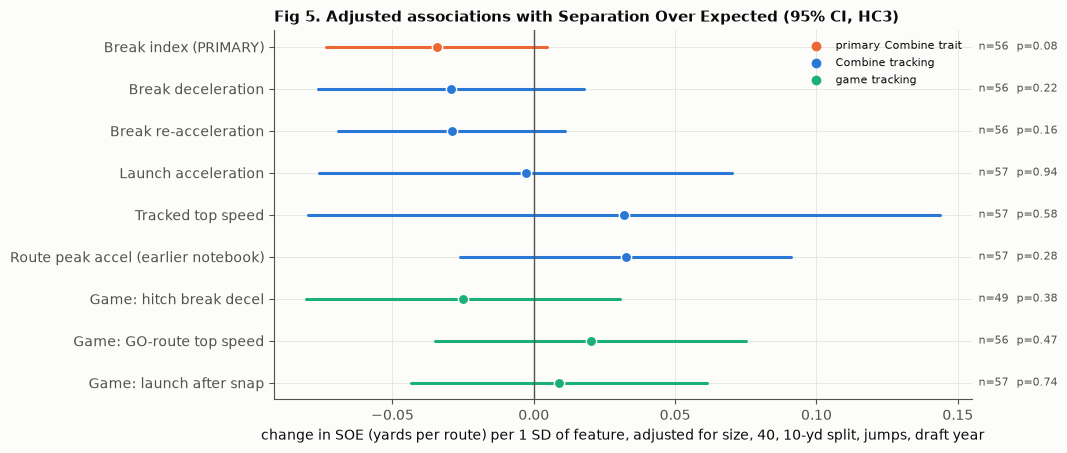

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.8))
lab = {"trk_break_index": "Break index (PRIMARY)", "trk_break_decel": "Break deceleration", "trk_break_reaccel": "Break re-acceleration",
       "trk_launch": "Launch acceleration", "trk_top_speed": "Tracked top speed", "trk_route_peak_accel": "Route peak accel (earlier notebook)",
       "g_hitch_decel": "Game: hitch break decel", "g_top_speed": "Game: GO-route top speed", "g_launch": "Game: launch after snap"}
a2 = assoc.iloc[::-1].reset_index(drop=True)
for i, r in a2.iterrows():
    col = C2 if r.family == "primary" else (C1 if r.source == "Combine tracking" else C3)
    ax.plot([r.ci_low, r.ci_high], [i, i], color=col, lw=2.2, solid_capstyle="round")
    ax.scatter(r.coef_yd_per_SD, i, color=col, s=55, zorder=3, edgecolor="white")
    ax.text(1.01, i, f"n={r.n}  p={r.p:.2f}", va="center", fontsize=8, color=INK2, transform=ax.get_yaxis_transform())
ax.axvline(0, color=INK2, lw=1); ax.set_yticks(range(len(a2))); ax.set_yticklabels([lab[f] for f in a2.feature])
ax.set_xlabel("change in SOE (yards per route) per 1 SD of feature, adjusted for size, 40, 10-yd split, jumps, draft year")
for c_, l_ in [(C2, "primary Combine trait"), (C1, "Combine tracking"), (C3, "game tracking")]:
    ax.scatter([], [], color=c_, label=l_)
ax.legend(frameon=False, loc="upper right", fontsize=8)
ax.set_title("Fig 5. Adjusted associations with Separation Over Expected (95% CI, HC3)", loc="left")
savefig(fig, "fig5_association_forest")

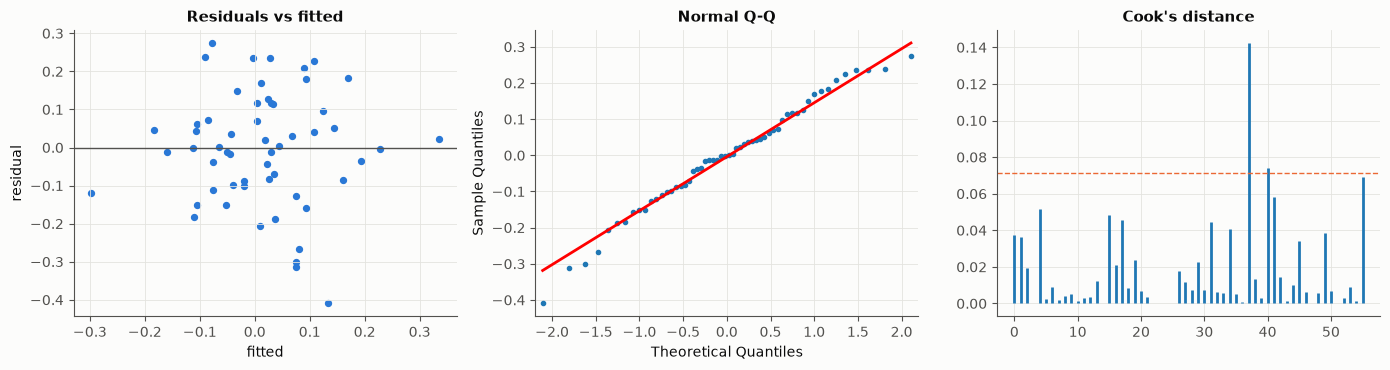

VIF: {'trk_break_index_z': 1.1, 'combine_height_z': 2.98, 'combine_weight_z': 3.11, 'forty_z': 1.21, 'ten_yd_split_z': 1.22, 'vertical_z': 1.74, 'broad_jump_z': 1.63}
Primary coef without 3 most influential players: -0.045 (p = 0.020)


In [27]:
# ---- Diagnostics for the primary model ---------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(prim.fittedvalues, prim.resid, color=C1, s=18); ax[0].axhline(0, color=INK2, lw=1)
ax[0].set_xlabel("fitted"); ax[0].set_ylabel("residual"); ax[0].set_title("Residuals vs fitted")
sm.qqplot(prim.resid, line="s", ax=ax[1], markersize=3); ax[1].set_title("Normal Q-Q")
# WLS = OLS on sqrt(weight)-scaled data, so influence is computed on the whitened design
infl = sm.OLS(prim.model.wendog, prim.model.wexog).fit().get_influence().cooks_distance[0]
ax[2].stem(infl, markerfmt=" ", basefmt=" "); ax[2].axhline(4 / len(infl), color=C2, ls="--", lw=1)
ax[2].set_title("Cook's distance"); fig.tight_layout(); savefig(fig, "diag_primary_model")
X = dprim[["trk_break_index_z"] + [c + "_z" for c in TRAD]]
vif = pd.Series([variance_inflation_factor(sm.add_constant(X).values, i + 1) for i in range(X.shape[1])], index=X.columns)
print("VIF:", vif.round(2).to_dict())
top_infl = np.argsort(infl)[::-1][:3]
drop = dprim.drop(dprim.index[top_infl])
f_drop = smf.wls(f"resid_mean ~ trk_break_index_z + {ADJ}", drop, weights=drop.precision_w).fit(cov_type="HC3")
print(f"Primary coef without 3 most influential players: {f_drop.params['trk_break_index_z']:+.3f} (p = {f_drop.pvalues['trk_break_index_z']:.3f})")
KEY.update(max_vif=float(vif.max()), prim_coef_drop3=f_drop.params["trk_break_index_z"])

In [28]:
# ---- Robustness of the primary estimate ---------------------------------------------------------
rob = []
def add(label, f, feat="trk_break_index_z"):
    rob.append({"specification": label, "n": int(f.nobs), "coef": f.params[feat], "ci_low": f.conf_int().loc[feat][0],
                "ci_high": f.conf_int().loc[feat][1], "p": f.pvalues[feat]})
add("Primary (WLS, >=50 routes, adjusted)", prim)
for mr in [25, 100, 200]:
    dd = master[master.routes >= mr].copy()
    for c in ["trk_break_index"] + TRAD: dd[c + "_z"] = zs(dd[c])
    add(f">= {mr} routes", fit_feature("trk_break_index", data=dd)[0])
add("Unadjusted (break index + draft year)", smf.wls("resid_mean ~ trk_break_index_z + C(draft_year)", dprim, weights=dprim.precision_w).fit(cov_type="HC3"))
dd = ana.copy(); add("+ draft capital (pick, drafted flag)", smf.wls(f"resid_mean ~ trk_break_index_z + {ADJ} + zs_pick + drafted",
    dd.assign(zs_pick=zs(dd.pick_filled)).dropna(subset=["trk_break_index_z"] + [c + "_z" for c in TRAD]),
    weights=dd.dropna(subset=["trk_break_index_z"] + [c + "_z" for c in TRAD]).precision_w).fit(cov_type="HC3"))
add("OLS on shrunk SOE (unweighted)", smf.ols(f"soe ~ trk_break_index_z + {ADJ}", ana).fit(cov_type="HC3"))
# context model without cushion (cushion may partly reflect defenders respecting the WR)
ctx2 = smf.ols(CTX.replace(" + cush + I(cush**2) + cush_miss", ""), data=sep).fit()
r2 = sep.assign(r2=ctx2.resid).groupby("nfl_id").r2.mean().rename("resid_nocush")
dd = ana.join(r2, on="nfl_id"); add("Context model without cushion", fit_feature("trk_break_index", data=dd, outcome="resid_nocush")[0])
# play-level mixed model with player random intercept (player covariates enter directly)
pl = sep[["nfl_id", "resid"]].merge(ana[["nfl_id", "draft_year", "trk_break_index_z"] + [c + "_z" for c in TRAD]], on="nfl_id").dropna()
mm = smf.mixedlm("resid ~ trk_break_index_z + " + " + ".join(c + "_z" for c in TRAD) + " + C(draft_year)", pl, groups=pl.nfl_id).fit()
rob.append({"specification": "Play-level mixed model (random intercept)", "n": pl.nfl_id.nunique(), "coef": mm.params["trk_break_index_z"],
            "ci_low": mm.conf_int().loc["trk_break_index_z"][0], "ci_high": mm.conf_int().loc["trk_break_index_z"][1], "p": mm.pvalues["trk_break_index_z"]})
for cov in ["MAN_COVERAGE", "ZONE_COVERAGE"]:
    s2 = sep[sep.team_coverage_man_zone.eq(cov)].groupby("nfl_id").resid.agg(["mean", "size"]).rename(columns={"mean": "rm_cov", "size": "n_cov"})
    dd = ana.join(s2, on="nfl_id"); dd["w_cov"] = 1 / (TAU2 + SIG2 / dd.n_cov)
    add(f"{cov.split('_')[0].title()} coverage only", fit_feature("trk_break_index", data=dd, outcome="rm_cov", weights="w_cov")[0])
robust = save_table(pd.DataFrame(rob), "13_primary_robustness"); display(robust)

/tmp/ipykernel_3597907/1141878412.py:17: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ctx2 = smf.ols(CTX.replace(" + cush + I(cush**2) + cush_miss", ""), data=sep).fit()


/tmp/ipykernel_3597907/1141878412.py:22: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  mm = smf.mixedlm("resid ~ trk_break_index_z + " + " + ".join(c + "_z" for c in TRAD) + " + C(draft_year)", pl, groups=pl.nfl_id).fit()


,specification,n,coef,ci_low,ci_high,p
0,"Primary (WLS, >=50 routes, adjusted)",56,-0.034,-0.073,0.005,0.084
1,>= 25 routes,60,-0.034,-0.071,0.002,0.068
2,>= 100 routes,50,-0.037,-0.076,0.003,0.069
3,>= 200 routes,36,-0.018,-0.069,0.033,0.487
4,Unadjusted (break index + draft year),56,-0.026,-0.073,0.022,0.288
5,"+ draft capital (pick, drafted flag)",56,-0.033,-0.076,0.011,0.138
6,OLS on shrunk SOE (unweighted),56,-0.022,-0.048,0.004,0.102
7,Context model without cushion,56,-0.014,-0.059,0.031,0.550
8,Play-level mixed model (random intercept),56,-0.031,-0.075,0.013,0.162
9,Man coverage only,56,-0.038,-0.096,0.020,0.202


**Statistical results.**
- **Primary hypothesis: not supported.** The break index estimate is −0.034 yd/route per SD (95% CI −0.073 to +0.005; bootstrap CI −0.073 to +0.014; p = 0.084; n = 56), with an incremental weighted R² of 0.03. The point estimate is *negative*, the opposite of H1. In football terms the CI rules out any benefit larger than about 0.005 yards per route, which is negligible.
- **Robustness:** the estimate is negative in all 11 specifications (route minimums of 25/100/200, draft capital added, unweighted OLS on shrunk SOE, no cushion adjustment, a play-level mixed model, man-only and zone-only coverage). Only one specification has p < 0.05: dropping the three most influential players gives −0.045, p = 0.02, again in the opposite direction to H1. We do not interpret this as harder breaks *hurting* separation. One plausible artefact is that heavier, possession-type receivers may plant harder in drills, and weight is the strongest SOE predictor (−0.10 yd/route per SD, p = 0.001).
- **Secondary family:** no feature survives FDR correction (all BH-adjusted p ≥ 0.74). Tracked and game top speed correlate with SOE unadjusted (r = 0.27 and 0.38), but those associations disappear once size is controlled. Smaller, faster receivers separate more, and size already captures that.
- **Diagnostics:** VIF ≤ 3.1. Residuals are approximately symmetric with no fan shape (Q-Q and residual plot above), and no single player dominates (Cook's distance plot).

### 9.1 What the null result does and does not rule out

A non-significant coefficient is not evidence of *no* relationship. Below we quantify (a) how much
measurement error in both variables can hide a true relationship, (b) the smallest effect this sample could detect,
and (c) which effect sizes the confidence interval actually excludes, after correcting for unreliability.

In [29]:
# ---- What does the null rule out? Measurement ceiling, power and disattenuated bounds ------------
# Break index = mean over hard-break drills of a per-drill index (mean of the two z-scores).
per_drill_idx = hb_z.mean(axis=1).unstack()
pr = per_drill_idx.corr().values; r_drill = np.nanmean([pr[i, j] for i in range(3) for j in range(i + 1, 3)])
k_drills = cfeat.loc[ana.loc[dprim.index, "nfl_id"], "trk_hb_drills"].mean()
rel_x = k_drills * r_drill / (1 + (k_drills - 1) * r_drill)          # Spearman-Brown over k drills
rel_y = float(ana.loc[dprim.index, "reliability"].mean())            # model-based SOE reliability
ceiling = np.sqrt(rel_x * rel_y)
df_res = prim.df_resid; t_ = prim.tvalues["trk_break_index_z"]
partial_r = t_ / np.sqrt(t_ ** 2 + df_res)
z_crit = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
r_mde_obs = np.tanh(z_crit / np.sqrt(df_res - 1))
need_n = lambda r_true: int(np.ceil((z_crit / np.arctanh(r_true * ceiling)) ** 2 + (prim.nobs - df_res) + 1))
power_tab = pd.DataFrame([
    ("Per-drill break-index agreement (mean pairwise r)", r_drill),
    ("Mean hard-break drills per WR (k)", k_drills),
    ("Reliability of break index (Spearman-Brown)", rel_x),
    ("Mean reliability of SOE in primary sample", rel_y),
    ("Max observable r if true r = 1 (attenuation ceiling)", ceiling),
    ("Observed partial r (break index | covariates)", partial_r),
    (f"Smallest observed partial |r| detectable, 80% power, n={int(prim.nobs)}", r_mde_obs),
    ("...equivalent TRUE r after attenuation", min(1.0, r_mde_obs / ceiling)),
    ("WRs needed to detect a true r = 0.30", need_n(0.30)),
    ("WRs needed to detect a true r = 0.20", need_n(0.20)),
    ("Coef CI upper bound, yd/route per SD (observed index)", KEY["prim_hi"]),
    ("Upper bound per SD of TRUE break skill (÷ sqrt(rel_x))", KEY["prim_hi"] / np.sqrt(rel_x)),
    ("Lower bound per SD of TRUE break skill (÷ sqrt(rel_x))", KEY["prim_lo"] / np.sqrt(rel_x)),
    ("Between-player SD of true SOE (tau, yd/route)", np.sqrt(TAU2)),
], columns=["quantity", "value"])
display(save_table(power_tab, "21_power_and_bounds"))
KEY.update(rel_break_index=rel_x, rel_soe_primary=rel_y, ceiling=ceiling, partial_r=partial_r, r_mde_obs=r_mde_obs,
           r_mde_true=min(1.0, r_mde_obs / ceiling), need_n_30=need_n(0.30), need_n_20=need_n(0.20),
           prim_hi_true=KEY["prim_hi"] / np.sqrt(rel_x), prim_lo_true=KEY["prim_lo"] / np.sqrt(rel_x))

,quantity,value
0,Per-drill break-index agreement (mean pairwise r),0.178
1,Mean hard-break drills per WR (k),2.804
2,Reliability of break index (Spearman-Brown),0.378
3,Mean reliability of SOE in primary sample,0.705
4,Max observable r if true r = 1 (attenuation ce...,0.516
5,Observed partial r (break index | covariates),-0.247
6,"Smallest observed partial |r| detectable, 80% ...",0.395
7,...equivalent TRUE r after attenuation,0.765
8,WRs needed to detect a true r = 0.30,334.000
9,WRs needed to detect a true r = 0.20,743.000


**Reading the table.**
- **Attenuation ceiling:** the break index has reliability 0.38 and SOE 0.71, so even a *perfect* true relationship could appear as at most r ≈ 0.52.
- **Power:** with n = 56 and 9 covariates, 80% power requires an observed partial |r| ≥ 0.40, which corresponds to a *true* r of about 0.77. **This study can only detect very large effects of underlying break skill.** Detecting a true r of 0.30 would need about 334 WRs, and r = 0.20 about 743.
- **What the CI does exclude:** a *beneficial* effect. Even after disattenuation, the upper bound is +0.008 yd/route per SD of true break skill, about 5% of the between-player SD of true separation skill (τ = 0.17). The lower bound (−0.12 yd/route) is wide, so a harmful association cannot be excluded either.

**Honest conclusion:** the data are inconsistent with the scouting hypothesis that better Combine-measured break mechanics translate into more NFL separation by any meaningful amount. They cannot rule out small effects, or effects of break skill measured with more reps.

## 10. Fair machine-learning comparison

**Goal:** estimate how well each feature set predicts SOE for *unseen players within these cohorts*, and stress-test generalisation to an *unseen draft class*. All predictors are available on draft day: Combine results and draft year only. No game-tracking, career or SOE-derived column enters any predictor set, which is asserted in code.

**10.1 Exploratory comparison (fixed target).** All models use the same 68 WRs (≥ 50 routes), the same shrunk SOE and the **same folds**.
- **A0:** training mean.
- **A1:** draft year.
- **B:** draft year + traditional Combine (height, weight, 40, 10-yd split, vertical, broad jump).
- **C:** draft year + five Combine-tracking features.
- **D:** B + C.

Ridge regression (α tuned by internal leave-one-out *within each training fold*) is the primary model; a random forest is the secondary one. Imputation and scaling are fitted inside folds. Validation is 5-fold CV repeated 20 times, plus leave-one-draft-year-out (LOYO).

**10.2 (below) repeats the key comparison with a fully fold-safe target**, because in 10.1 the SOE context model and shrinkage were fitted on all routes, including test players' routes.

In [30]:
TRK_ML = ["trk_break_decel", "trk_break_reaccel", "trk_launch", "trk_top_speed", "trk_route_peak_accel"]
SPECS = {"A0 Training mean": None, "A1 Draft year": [], "B Traditional Combine": TRAD,
         "C Combine tracking": TRK_ML, "D Traditional + tracking": TRAD + TRK_ML}

def make_pipe(num, algo):
    pre = ColumnTransformer([("dy", OneHotEncoder(handle_unknown="ignore"), ["draft_year"])] +
                            ([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num)] if num else []))
    est = RidgeCV(alphas=np.logspace(-2, 3, 40)) if algo == "ridge" else \
          RandomForestRegressor(n_estimators=400, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1)
    return Pipeline([("pre", pre), ("m", est)])

def evaluate(df, target, algos=("ridge", "rf"), n_rep=20, seed=SEED):
    """Same RepeatedKFold splits for every model; pooled out-of-fold metrics per repeat + LOYO."""
    df = df.reset_index(drop=True); y = df[target].to_numpy()
    rkf = RepeatedKFold(n_splits=5, n_repeats=n_rep, random_state=seed)
    splits = list(rkf.split(df))
    rep_rows, loyo_rows = [], []
    for algo in algos:
        for name, feats in SPECS.items():
            if feats is None and algo != algos[0]:
                continue
            cols = ["draft_year"] + (feats or [])
            for rep in range(n_rep):
                pred = np.empty(len(y))
                for tr, te in splits[rep * 5:(rep + 1) * 5]:
                    mdl = DummyRegressor() if feats is None else make_pipe(feats, algo)
                    mdl.fit(df.loc[tr, cols], y[tr]); pred[te] = mdl.predict(df.loc[te, cols])
                rep_rows.append({"algo": "baseline" if feats is None else algo, "model": name, "repeat": rep,
                                 "rmse": mean_squared_error(y, pred) ** .5, "mae": mean_absolute_error(y, pred), "r2": r2_score(y, pred)})
            for yr in sorted(df.draft_year.unique()):
                tr, te = np.flatnonzero(df.draft_year != yr), np.flatnonzero(df.draft_year == yr)
                mdl = DummyRegressor() if feats is None else make_pipe(feats, algo)
                mdl.fit(df.loc[tr, cols], y[tr]); p_ = mdl.predict(df.loc[te, cols])
                loyo_rows.append({"algo": "baseline" if feats is None else algo, "model": name, "heldout_year": yr, "n_test": len(te),
                                  "rmse": mean_squared_error(y[te], p_) ** .5, "mae": mean_absolute_error(y[te], p_)})
    return pd.DataFrame(rep_rows), pd.DataFrame(loyo_rows)

def summarise(reps, loyo):
    s = reps.groupby(["algo", "model"]).agg(n_repeats=("rmse", "size"), rmse=("rmse", "mean"), rmse_sd=("rmse", "std"),
                                             mae=("mae", "mean"), r2=("r2", "mean"), r2_sd=("r2", "std"))
    l = loyo.groupby(["algo", "model"]).agg(loyo_rmse=("rmse", "mean"))
    return s.join(l)

def paired(reps, a, b, algo):
    x = reps[(reps.model == a) & (reps.algo.isin([algo, "baseline"]))].set_index("repeat").rmse
    z = reps[(reps.model == b) & (reps.algo.isin([algo, "baseline"]))].set_index("repeat").rmse
    d = (x - z).dropna()
    return {"comparison": f"{a} minus {b}", "algo": algo, "mean_rmse_diff": d.mean(), "p2.5": d.quantile(.025),
            "p97.5": d.quantile(.975), "share_repeats_first_better": (d < 0).mean()}

ml = master[master.routes >= MIN_ROUTES].copy()
t0 = time.time(); reps, loyo = evaluate(ml, "soe")
print(f"SOE model comparison: n = {len(ml)} WRs, {time.time()-t0:.0f}s")
ml_sum = save_table(summarise(reps, loyo).reset_index(), "14_model_comparison_soe"); display(ml_sum)
pairs_soe = pd.DataFrame([paired(reps, "D Traditional + tracking", "B Traditional Combine", a) for a in ["ridge", "rf"]] +
                         [paired(reps, "C Combine tracking", "A1 Draft year", a) for a in ["ridge", "rf"]] +
                         [paired(reps, "B Traditional Combine", "A1 Draft year", a) for a in ["ridge", "rf"]])
display(save_table(pairs_soe, "15_paired_rmse_soe"))
save_table(loyo, "16_loyo_by_year_soe"); display(loyo.pivot_table(index=["algo", "model"], columns="heldout_year", values="rmse"))
KEY.update(ml_n=len(ml), ml=ml_sum.round(4).to_dict("records"), ml_pairs=pairs_soe.round(4).to_dict("records"))

SOE model comparison: n = 68 WRs, 308s


,algo,model,n_repeats,rmse,rmse_sd,mae,r2,r2_sd,loyo_rmse
0,baseline,A0 Training mean,20,0.144,0.001,0.114,-0.029,0.018,0.141
1,rf,A1 Draft year,20,0.147,0.002,0.115,-0.068,0.033,0.141
2,rf,B Traditional Combine,20,0.125,0.003,0.096,0.223,0.036,0.120
3,rf,C Combine tracking,20,0.145,0.004,0.116,-0.040,0.054,0.137
4,rf,D Traditional + tracking,20,0.127,0.003,0.098,0.198,0.038,0.121
5,ridge,A1 Draft year,20,0.145,0.001,0.114,-0.035,0.018,0.141
6,ridge,B Traditional Combine,20,0.124,0.004,0.095,0.245,0.047,0.115
7,ridge,C Combine tracking,20,0.150,0.006,0.118,-0.119,0.089,0.143
8,ridge,D Traditional + tracking,20,0.129,0.004,0.099,0.180,0.058,0.117


,comparison,algo,mean_rmse_diff,p2.5,p97.5,share_repeats_first_better
0,D Traditional + tracking minus B Traditional C...,ridge,0.005,0.000,0.010,0.050
1,D Traditional + tracking minus B Traditional C...,rf,0.002,-0.000,0.005,0.050
2,C Combine tracking minus A1 Draft year,ridge,0.006,-0.001,0.020,0.050
3,C Combine tracking minus A1 Draft year,rf,-0.002,-0.009,0.005,0.800
4,B Traditional Combine minus A1 Draft year,ridge,-0.021,-0.025,-0.016,1.000
5,B Traditional Combine minus A1 Draft year,rf,-0.022,-0.024,-0.017,1.000


heldout_year                       2023  2024  2025
algo     model                                     
baseline A0 Training mean         0.165 0.120 0.137
rf       A1 Draft year            0.165 0.119 0.137
         B Traditional Combine    0.139 0.124 0.097
         C Combine tracking       0.166 0.115 0.129
         D Traditional + tracking 0.145 0.120 0.100
ridge    A1 Draft year            0.165 0.120 0.137
         B Traditional Combine    0.138 0.111 0.096
         C Combine tracking       0.175 0.119 0.135
         D Traditional + tracking 0.141 0.107 0.104

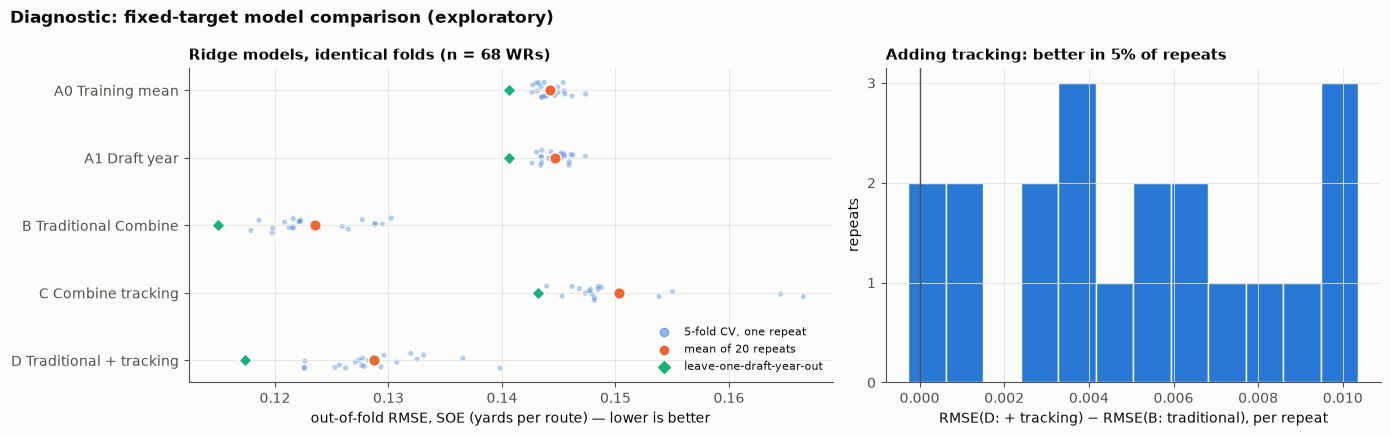

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
order = list(SPECS)
rr = reps[reps.algo.isin(["ridge", "baseline"])]
for i, mname in enumerate(order):
    v = rr[rr.model == mname].rmse
    ax[0].scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-.12, .12, len(v)), color=C1, alpha=.35, s=14, edgecolor="none")
    ax[0].scatter(v.mean(), i, color=C2, s=70, zorder=3, edgecolor="white")
    lo_ = loyo[(loyo.model == mname) & loyo.algo.isin(["ridge", "baseline"])].rmse.mean()
    ax[0].scatter(lo_, i, marker="D", color=C3, s=45, zorder=3, edgecolor="white")
ax[0].set_yticks(range(len(order))); ax[0].set_yticklabels(order); ax[0].invert_yaxis()
ax[0].scatter([], [], color=C1, alpha=.5, label="5-fold CV, one repeat"); ax[0].scatter([], [], color=C2, label="mean of 20 repeats")
ax[0].scatter([], [], marker="D", color=C3, label="leave-one-draft-year-out")
ax[0].legend(frameon=False, fontsize=8, loc="lower right"); ax[0].set_xlabel("out-of-fold RMSE, SOE (yards per route) — lower is better")
ax[0].set_title(f"Ridge models, identical folds (n = {len(ml)} WRs)", loc="left")
dd = (rr[rr.model == "D Traditional + tracking"].set_index("repeat").rmse - rr[rr.model == "B Traditional Combine"].set_index("repeat").rmse)
ax[1].hist(dd, bins=12, color=C1, edgecolor="white"); ax[1].axvline(0, color=INK2, lw=1)
ax[1].set_xlabel("RMSE(D: + tracking) − RMSE(B: traditional), per repeat"); ax[1].set_ylabel("repeats")
ax[1].yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
ax[1].set_title(f"Adding tracking: better in {(dd < 0).mean():.0%} of repeats", loc="left")
fig.suptitle("Diagnostic: fixed-target model comparison (exploratory)", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "diag_fixed_target_models")

**Exploratory comparison (fixed target; diagnostic figure above).**
- **Traditional Combine predicts SOE modestly.** Ridge model B reaches RMSE 0.124 vs 0.144 for the training mean (out-of-fold R² 0.25), mostly through size.
- **Tracking alone (C) is worse than predicting the mean** (R² −0.12).
- **Adding tracking (D vs B) increased RMSE** in 19 of 20 repeats.

### 10.2 Fully fold-safe comparison and single-feature additions

**Fold-safe target.** For every split, the play-level context model and the REML shrinkage are refitted using **only the plays of non-test players**. Test players' SOE is then computed with those training-only coefficients, so no information about test players' separation reaches the model in any form.

**Single-feature additions.** Adding five noisy features at once can mask one useful feature, so we also test pre-specified *single* additions to B: the primary break index, and tracked top speed (the one trait that transferred).

**Uncertainty.**
- **LOYO:** each held-out draft class reports the change in RMSE versus B, with a 95% CI from a paired bootstrap over the test-class players.
- **Repeated CV:** we report the share of repeats in which each model beats B.

In [32]:
# ---- Fully fold-safe comparison: the SOE target itself is rebuilt inside every training fold ----
CAT = ["route_ran", "cov", "align", "formation"]
assert not any(f.startswith(("g_", "career", "soe", "routes")) for f in TRAD + TRK_ML), "post-draft info in predictors"

def foldsafe_target(test_ids):
    """Fit the context model on plays of NON-test players only; shrink with training-only tau/sigma."""
    tr = sep[~sep.nfl_id.isin(test_ids)]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")   # route x coverage design is rank-deficient by construction
        fit = smf.ols(CTX, data=tr).fit()
    d = sep.copy()
    for c in CAT:                                     # unseen category levels -> training mode
        seen = set(tr[c].unique()); d.loc[~d[c].isin(seen), c] = tr[c].mode()[0]
    d["r_fs"] = d.separation_at_pass_forward - fit.predict(d)
    g = d.groupby("nfl_id").r_fs.agg(["mean", "size"])
    dtr = d[~d.nfl_id.isin(test_ids)]                 # same REML random-intercept model as the main SOE
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        rf = smf.mixedlm("r_fs ~ 1", dtr, groups=dtr["nfl_id"]).fit(reml=True)
    tau2, sig2 = float(rf.cov_re.iloc[0, 0]), float(rf.scale)
    mu = float(rf.fe_params.iloc[0])
    return mu + (g["mean"] - mu) * tau2 / (tau2 + sig2 / g["size"])

FS_SPECS = {"A1 Draft year": [], "B Traditional Combine": TRAD, "B + break index": TRAD + ["trk_break_index"],
            "B + tracked top speed": TRAD + ["trk_top_speed"], "D Traditional + all tracking": TRAD + TRK_ML}
mlfs = master[master.routes >= MIN_ROUTES].reset_index(drop=True)

def fs_split(tr_idx, te_idx):
    y_all = foldsafe_target(set(mlfs.loc[te_idx, "nfl_id"]))
    y_tr = mlfs.loc[tr_idx, "nfl_id"].map(y_all).to_numpy(); y_te = mlfs.loc[te_idx, "nfl_id"].map(y_all).to_numpy()
    out = {}
    for name, feats in FS_SPECS.items():
        mdl = make_pipe(feats, "ridge"); cols = ["draft_year"] + feats
        mdl.fit(mlfs.loc[tr_idx, cols], y_tr); out[name] = mdl.predict(mlfs.loc[te_idx, cols])
    return y_te, out

t0 = time.time(); N_REP_FS = 10
fs_rows = []
for rep, (tr, te) in enumerate(RepeatedKFold(n_splits=5, n_repeats=N_REP_FS, random_state=SEED).split(mlfs)):
    y_te, preds = fs_split(tr, te)
    for name, p in preds.items():
        fs_rows += [{"repeat": rep // 5, "model": name, "y": yy, "p": pp} for yy, pp in zip(y_te, p)]
fs = pd.DataFrame(fs_rows)
fs_cv = fs.groupby(["model", "repeat"]).apply(lambda d: pd.Series({"rmse": mean_squared_error(d.y, d.p) ** .5,
                                                                     "mae": mean_absolute_error(d.y, d.p)})).reset_index()
base = fs_cv[fs_cv.model == "B Traditional Combine"].set_index("repeat")
fs_cv_sum = fs_cv.groupby("model").agg(rmse=("rmse", "mean"), rmse_sd=("rmse", "std"), mae=("mae", "mean")).reindex(FS_SPECS)
fs_cv_sum["share_repeats_beating_B"] = [ (fs_cv[fs_cv.model == m].set_index("repeat").rmse < base.rmse).mean() for m in FS_SPECS]
print(f"Fold-safe repeated CV ({N_REP_FS}x5, n = {len(mlfs)}) in {time.time()-t0:.0f}s")
display(save_table(fs_cv_sum.reset_index(), "22_foldsafe_cv"))

# Leave-one-draft-year-out with paired player bootstrap of the error difference vs model B
rng = np.random.default_rng(SEED); loyo_fs = []
for yr in sorted(mlfs.draft_year.unique()):
    tr, te = np.flatnonzero(mlfs.draft_year != yr), np.flatnonzero(mlfs.draft_year == yr)
    y_te, preds = fs_split(tr, te)
    eB = (preds["B Traditional Combine"] - y_te) ** 2
    for name, p in preds.items():
        e = (p - y_te) ** 2
        bs = [np.sqrt(e[i].mean()) - np.sqrt(eB[i].mean()) for i in (rng.integers(0, len(e), len(e)) for _ in range(2000))]
        loyo_fs.append({"heldout_year": yr, "n_test": len(te), "model": name, "rmse": np.sqrt(e.mean()),
                        "mae": np.abs(p - y_te).mean(), "d_rmse_vs_B": np.sqrt(e.mean()) - np.sqrt(eB.mean()),
                        "ci_low": np.percentile(bs, 2.5), "ci_high": np.percentile(bs, 97.5)})
loyo_fs = save_table(pd.DataFrame(loyo_fs), "23_foldsafe_loyo")
print("RMSE change vs model B, in milli-yards per route (negative = better than B):")
display((1000 * loyo_fs.pivot_table(index="model", columns="heldout_year", values="d_rmse_vs_B")).reindex(FS_SPECS).round(1))
print("Absolute LOYO RMSE by held-out class:")
display(loyo_fs.pivot_table(index="model", columns="heldout_year", values="rmse").reindex(FS_SPECS).round(4))
cons = loyo_fs[loyo_fs.model != "B Traditional Combine"].groupby("model").agg(
    years_better_than_B=("d_rmse_vs_B", lambda v: int((v < 0).sum())), mean_d_rmse=("d_rmse_vs_B", "mean"),
    years_CI_excludes_0=("ci_high", lambda v: int((v < 0).sum())))
cons["mean_d_rmse_x1000"] = 1000 * cons.mean_d_rmse
display(cons)
KEY.update(fs_cv=fs_cv_sum.round(4).reset_index().to_dict("records"), fs_loyo=loyo_fs.round(4).to_dict("records"),
           fs_cons=cons.reset_index().to_dict("records"))

Fold-safe repeated CV (10x5, n = 68) in 238s


,model,rmse,rmse_sd,mae,share_repeats_beating_B
0,A1 Draft year,0.141,0.002,0.113,0.000
1,B Traditional Combine,0.119,0.004,0.094,0.000
2,B + break index,0.119,0.005,0.093,0.500
3,B + tracked top speed,0.121,0.005,0.096,0.100
4,D Traditional + all tracking,0.125,0.006,0.098,0.000


RMSE change vs model B, in milli-yards per route (negative = better than B):


heldout_year,2023,2024,2025
model,,,
A1 Draft year,23.300,10.700,53.700
B Traditional Combine,0.000,0.000,0.000
B + break index,-2.200,-0.200,-0.100
B + tracked top speed,2.300,-2.200,0.900
D Traditional + all tracking,8.900,-3.700,13.100


Absolute LOYO RMSE by held-out class:


heldout_year,2023,2024,2025
model,,,
A1 Draft year,0.210,0.127,0.233
B Traditional Combine,0.187,0.117,0.179
B + break index,0.184,0.117,0.179
B + tracked top speed,0.189,0.115,0.180
D Traditional + all tracking,0.196,0.113,0.192


,years_better_than_B,mean_d_rmse,years_CI_excludes_0,mean_d_rmse_x1000
model,,,,
A1 Draft year,0,0.029,0,29.212
B + break index,3,-0.001,0,-0.816
B + tracked top speed,1,0.000,0,0.340
D Traditional + all tracking,1,0.006,0,6.115


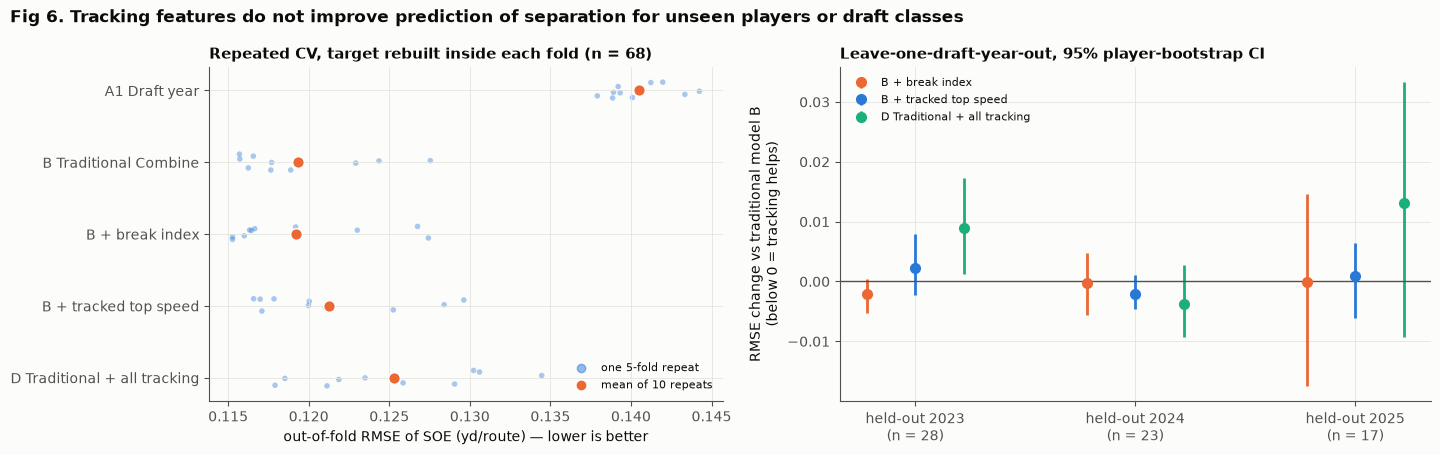

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(14.5, 4.6), gridspec_kw={"width_ratios": [1, 1.15]})
names = list(FS_SPECS)
for i, m in enumerate(names):
    v = fs_cv[fs_cv.model == m].rmse
    ax[0].scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-.12, .12, len(v)), color=C1, alpha=.4, s=16, edgecolor="none")
    ax[0].scatter(v.mean(), i, color=C2, s=70, zorder=3, edgecolor="white")
ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels(names); ax[0].invert_yaxis()
ax[0].scatter([], [], color=C1, alpha=.5, label="one 5-fold repeat"); ax[0].scatter([], [], color=C2, label=f"mean of {N_REP_FS} repeats")
ax[0].legend(frameon=False, fontsize=8, loc="lower right")
ax[0].set_xlabel("out-of-fold RMSE of SOE (yd/route) — lower is better")
ax[0].set_title(f"Repeated CV, target rebuilt inside each fold (n = {len(mlfs)})", loc="left")
cmp_m = ["B + break index", "B + tracked top speed", "D Traditional + all tracking"]; cols = [C2, C1, C3]
yrs = sorted(loyo_fs.heldout_year.unique())
for j, (m, c) in enumerate(zip(cmp_m, cols)):
    sub = loyo_fs[loyo_fs.model == m].set_index("heldout_year").loc[yrs]
    xs = np.arange(len(yrs)) + (j - 1) * 0.22
    ax[1].errorbar(xs, sub.d_rmse_vs_B, yerr=[sub.d_rmse_vs_B - sub.ci_low, sub.ci_high - sub.d_rmse_vs_B],
                   fmt="o", color=c, ms=7, lw=2, capsize=0, label=m)
ax[1].axhline(0, color=INK2, lw=1); ax[1].set_xticks(range(len(yrs)))
ax[1].set_xticklabels([f"held-out {y}\n(n = {int(loyo_fs[loyo_fs.heldout_year == y].n_test.iloc[0])})" for y in yrs])
ax[1].set_ylabel("RMSE change vs traditional model B\n(below 0 = tracking helps)")
ax[1].legend(frameon=False, fontsize=8, loc="upper left")
ax[1].set_title("Leave-one-draft-year-out, 95% player-bootstrap CI", loc="left")
fig.suptitle("Fig 6. Tracking features do not improve prediction of separation for unseen players or draft classes", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "fig6_model_comparison")

**Fold-safe results (Fig 6).**
- **Traditional Combine (B) is the model to beat.** It beats draft-year-only in every CV repeat (RMSE 0.119 vs 0.141) and in every held-out class.
- **All tracking (D) is worse.** RMSE is 0.125 and D never beats B across the 10 CV repeats. In LOYO it is worse for 2023 (+8.9 milli-yd/route; CI excludes 0 in the harmful direction) and 2025 (+13.1), and better only for 2024 (−3.7).
- **B + tracked top speed shows no gain:** it beats B in 1 of 10 repeats and 1 of 3 held-out classes, with a mean change of +0.3 milli-yd/route.
- **B + break index shows no meaningful gain.** It beats B in 5 of 10 repeats and is marginally better in all 3 held-out classes, but by only 2.2, 0.2 and 0.1 milli-yd/route (at most ≈1% of RMSE). Every CI includes 0, and the gain comes from the *negative* (counter-hypothesis) coefficient.

**Conclusion:** none of the tracking features yields a consistent, practically meaningful improvement in predicting separation for unseen players or unseen draft classes. This matches the fixed-target analysis and the reliability ceiling.

## 11. Secondary outcome and verification of the earlier notebook: career usage

The earlier exploration reported that average route-drill peak acceleration and Dagger Route Left
peak acceleration were positively associated with `log1p(career offensive snaps)` and
`log1p(career games started)` after adjusting for draft year. That analysis is re-run here exactly
(same model form, HC3 SEs, BH over the same six tests), then extended with the traditional-Combine
adjustment. Career totals reflect exposure, draft capital and opportunity, so they are a secondary outcome only.

In [34]:
leg = master.copy()
leg["log_snaps"] = np.log1p(leg.career_offensive_snaps); leg["log_starts"] = np.log1p(leg.career_games_started)
rows = []
for feat in ["legacy_dagger_peak_accel", "trk_route_peak_accel", "legacy_route_best_peak_accel"]:
    for out in ["log_snaps", "log_starts"]:
        for adj_name, adj in [("draft year (as earlier)", "C(draft_year)"),
                              ("+ traditional Combine", "C(draft_year) + " + " + ".join(TRAD)),
                              ("+ traditional + draft capital", "C(draft_year) + " + " + ".join(TRAD) + " + np.log(pick_filled) + drafted")]:
            d = leg[[feat, out, "draft_year", "pick_filled", "drafted"] + TRAD].dropna() if "traditional" in adj_name else leg[[feat, out, "draft_year"]].dropna()
            f = smf.ols(f"{out} ~ {feat} + {adj}", d).fit(cov_type="HC3")
            rows.append({"feature": feat, "outcome": out, "adjustment": adj_name, "n": int(f.nobs), "coef": f.params[feat],
                         "ci_low": f.conf_int().loc[feat][0], "ci_high": f.conf_int().loc[feat][1], "p": f.pvalues[feat]})
legacy = pd.DataFrame(rows)
for adj_name in legacy.adjustment.unique():
    m_ = legacy.adjustment.eq(adj_name); legacy.loc[m_, "p_BH"] = multipletests(legacy.loc[m_, "p"], method="fdr_bh")[1]
display(save_table(legacy, "17_career_verification"))
KEY["legacy"] = legacy.round(4).to_dict("records")

,feature,outcome,adjustment,n,coef,ci_low,ci_high,p,p_BH
0,legacy_dagger_peak_accel,log_snaps,draft year (as earlier),106,1.365,0.434,2.295,0.004,0.006
1,legacy_dagger_peak_accel,log_snaps,+ traditional Combine,87,1.884,0.949,2.820,0.000,0.000
2,legacy_dagger_peak_accel,log_snaps,+ traditional + draft capital,87,0.854,0.050,1.658,0.037,0.141
3,legacy_dagger_peak_accel,log_starts,draft year (as earlier),106,0.840,0.399,1.280,0.000,0.001
4,legacy_dagger_peak_accel,log_starts,+ traditional Combine,87,0.971,0.457,1.486,0.000,0.001
5,legacy_dagger_peak_accel,log_starts,+ traditional + draft capital,87,0.487,-0.011,0.985,0.055,0.141
6,trk_route_peak_accel,log_snaps,draft year (as earlier),106,3.017,1.383,4.652,0.000,0.001
7,trk_route_peak_accel,log_snaps,+ traditional Combine,87,2.847,0.790,4.903,0.007,0.013
8,trk_route_peak_accel,log_snaps,+ traditional + draft capital,87,1.455,-0.171,3.082,0.079,0.141
9,trk_route_peak_accel,log_starts,draft year (as earlier),106,1.455,0.665,2.245,0.000,0.001


In [35]:
cm = master.dropna(subset=["career_offensive_snaps"]).copy(); cm["log_snaps"] = np.log1p(cm.career_offensive_snaps)
reps_c, loyo_c = evaluate(cm, "log_snaps", algos=("ridge",))
car_sum = save_table(summarise(reps_c, loyo_c).reset_index(), "18_model_comparison_career"); display(car_sum)
display(pd.DataFrame([paired(reps_c, "D Traditional + tracking", "B Traditional Combine", "ridge")]))
display(loyo_c.pivot_table(index="model", columns="heldout_year", values="rmse"))
KEY.update(car_n=len(cm), car=car_sum.round(4).to_dict("records"), car_pair=paired(reps_c, "D Traditional + tracking", "B Traditional Combine", "ridge"))

,algo,model,n_repeats,rmse,rmse_sd,mae,r2,r2_sd,loyo_rmse
0,baseline,A0 Training mean,20,2.722,0.022,2.307,-0.021,0.016,2.840
1,ridge,A1 Draft year,20,2.628,0.031,2.194,0.048,0.023,2.832
2,ridge,B Traditional Combine,20,2.394,0.037,1.952,0.210,0.024,2.687
3,ridge,C Combine tracking,20,2.569,0.039,2.101,0.091,0.027,2.850
4,ridge,D Traditional + tracking,20,2.398,0.044,1.951,0.208,0.029,2.675


,comparison,algo,mean_rmse_diff,p2.5,p97.5,share_repeats_first_better
0,D Traditional + tracking minus B Traditional C...,ridge,0.004,-0.058,0.045,0.500


heldout_year,2023,2024,2025
model,,,
A0 Training mean,2.932,2.326,3.261
A1 Draft year,2.904,2.331,3.261
B Traditional Combine,2.886,2.213,2.962
C Combine tracking,3.000,2.180,3.369
D Traditional + tracking,2.855,2.062,3.109


**Verification of the earlier notebook.**
- **The earlier result replicates exactly as specified.** With draft-year adjustment only, route peak acceleration is associated with log career snaps (coef 3.02 per yd/s², p < 0.001) and starts. So is Dagger peak acceleration (1.37, p = 0.004). Route-*best* peak acceleration is not (p = 0.10).
- **It survives the traditional-Combine adjustment** (2.85, p = 0.007).
- **It roughly halves once draft capital is added** (1.46, p = 0.079; Dagger 0.85, p = 0.037), and *no* feature survives BH correction in that specification (all BH-adjusted p ≥ 0.14). Teams appear to already price some of this into draft slot, and draft slot drives snaps.
- **No predictive gain:** for log career snaps, model D vs B shows ΔRMSE +0.004, with D better in only half the repeats. LOYO gains are tiny (2.675 vs 2.687).
- **Interpretation:** the earlier "acceleration predicts usage" finding is better described as *partly confounded by draft capital, with no demonstrated predictive value*. Note also that the same route peak acceleration feature shows no association with separation (§9).

## 11b. Inside NFL games: do break skill and speed relate to separation at all?

If *in-game* break mechanics (reliably measured over dozens of reps) do not relate to separation either, the
problem is not only Combine measurement: break deceleration is then not how receivers win at the moment of the throw.
**Design:** for each WR, routes of a type are randomly split in half. The trait is measured on one half and separation
residuals on the other, then the halves are swapped and averaged. This prevents shared play-level noise
(e.g. a well-timed play that shows both a sharp break and good separation) from manufacturing a correlation.

In [36]:
# ---- Within NFL games: does break skill relate to separation on the routes where it matters? -----
# Split-plays design: the movement trait is measured on one random half of a WR's routes and
# separation (context residual) on the other half, so shared play-level noise cannot create a correlation.
def split_trait_vs_sep(route, trait, min_trait=5, min_sep=10, need_break=False, agg="median"):
    d = sep[sep.route_ran.eq(route)][TRK_KEY + ["resid"]].merge(groutes[TRK_KEY + ["break_found", trait]], on=TRK_KEY, how="inner")
    d = d.sample(frac=1, random_state=SEED); d["half"] = d.groupby("nfl_id").cumcount() % 2
    out = []
    for h in (0, 1):
        tsrc = d[d.half == h]
        if need_break:
            tsrc = tsrc[tsrc.break_found.eq(1)]
        t_ = tsrc.groupby("nfl_id")[trait].agg([agg, "size"]); t_ = t_[t_["size"] >= min_trait][agg].rename("trait")
        s_ = d[d.half != h].groupby("nfl_id").resid.agg(["mean", "size"]); s_ = s_[s_["size"] >= min_sep]["mean"].rename("sep")
        out.append(pd.concat([t_, s_], axis=1, join="inner"))
    m = pd.concat(out).groupby(level=0).mean()          # average the two half-swaps per WR
    m = m.join(master.set_index("nfl_id")[["combine_weight"]])
    r, p = stats.pearsonr(m.trait, m.sep); lo, hi = boot_corr(m.trait, m.sep)
    pr = smf.ols("sep ~ trait + combine_weight", m.assign(trait=zs(m.trait), sep=m.sep)).fit(cov_type="HC3")
    return {"route": route, "trait": trait, "n_WRs": len(m), "r": r, "ci_low": lo, "ci_high": hi, "p": p,
            "coef_per_SD_adj_weight": pr.params["trait"], "p_adj_weight": pr.pvalues["trait"]}

gb = pd.DataFrame([split_trait_vs_sep("HITCH", "decel_rate", need_break=True),
                   split_trait_vs_sep("GO", "route_peak_speed", agg="max")])
display(save_table(gb, "24_game_trait_vs_separation"))
KEY["game_break"] = gb.round(4).to_dict("records")

,route,trait,n_WRs,r,ci_low,ci_high,p,coef_per_SD_adj_weight,p_adj_weight
0,HITCH,decel_rate,53,-0.016,-0.294,0.278,0.907,0.001,0.977
1,GO,route_peak_speed,62,-0.243,-0.413,-0.060,0.057,-0.086,0.000


**Result.**
- **Hitch-break deceleration does not predict hitch separation on other plays:** r = −0.02 (95% CI −0.29 to 0.28, n = 53); adjusted for weight, +0.001 yd/route per SD (p = 0.98). Even a reliably measured, in-game break trait is not associated with being more open when the ball is thrown on hitches.
- **GO-route speed shows a negative relationship with GO-route separation:** r = −0.24 (bootstrap CI −0.41 to −0.06, parametric p = 0.057); adjusted for weight, −0.09 yd/route per SD (p < 0.001). One plausible explanation is that defenses respect speed with safety help and bail technique beyond what cushion captures. Another is that separation *at pass forward* is measured before deep speed has played out. This is exploratory and we do not interpret it causally.

**Implication for scouts:** the value of speed shows up in *how fast a WR runs in games*, which the tracker captures better than the stopwatch, not in separation at the release point. Break mechanics showed no measurable link to that separation at the Combine *or* in games.

## 12. Football application: what a scout can actually use

The one Combine tracking signal that survived every check is **top speed**: it is reliable, it reappears in NFL games, and it improves on the 40. Below we ask whether tracked top speed *corrects* the stopwatch, i.e. whether prospects who run faster on the tracker than their 40 implies also play faster than their 40 implies.

Tracked speed beyond the 40 vs game speed beyond the 40: r = 0.30 [0.06, 0.52], p = 0.0166, n = 62; Spearman 0.31; trimmed r = 0.39 (n = 61)
Tracked speed beyond the 40 vs SOE: r = 0.22, p = 0.083, n = 62


Matched pairs: 93 (from 42 WRs). Tracked-faster WR also faster on NFL GO routes in 70% of pairs (permutation p = 0.030); mean game gap +0.26 yd/s.


,pair,player,draft,role,40 (s),tracked top (yd/s),beyond 40 (yd/s),NFL GO p90 (yd/s),90% CI,GO routes,SOE (yd/route),SOE ±SD,routes
0,1,Jimmy Horn,2025,tracked faster,4.460,11.340,0.230,9.610,9.43–10.03,17,0.130,0.130,68
1,1,Jamari Thrash,2024,tracked slower,4.460,10.880,-0.230,8.530,8.37–8.62,52,-0.080,0.100,192
2,2,Jayden Reed,2023,tracked faster,4.450,11.300,0.170,9.340,9.22–9.50,100,0.090,0.060,773
3,2,Malik Washington,2024,tracked slower,4.470,11.010,-0.080,8.570,8.26–8.69,80,0.200,0.070,507
4,3,Demario Douglas,2023,tracked faster,4.440,11.310,0.150,8.940,8.79–9.14,125,0.180,0.060,828
5,3,Luke McCaffrey,2024,tracked slower,4.460,11.030,-0.080,9.020,8.71–9.28,54,0.150,0.090,262
6,4,Jalin Hyatt,2023,tracked faster,4.400,11.630,0.380,9.320,9.14–9.45,196,0.120,0.070,549
7,4,Jaylin Noel,2025,tracked slower,4.390,11.330,0.050,9.100,8.46–9.40,19,0.020,0.110,174


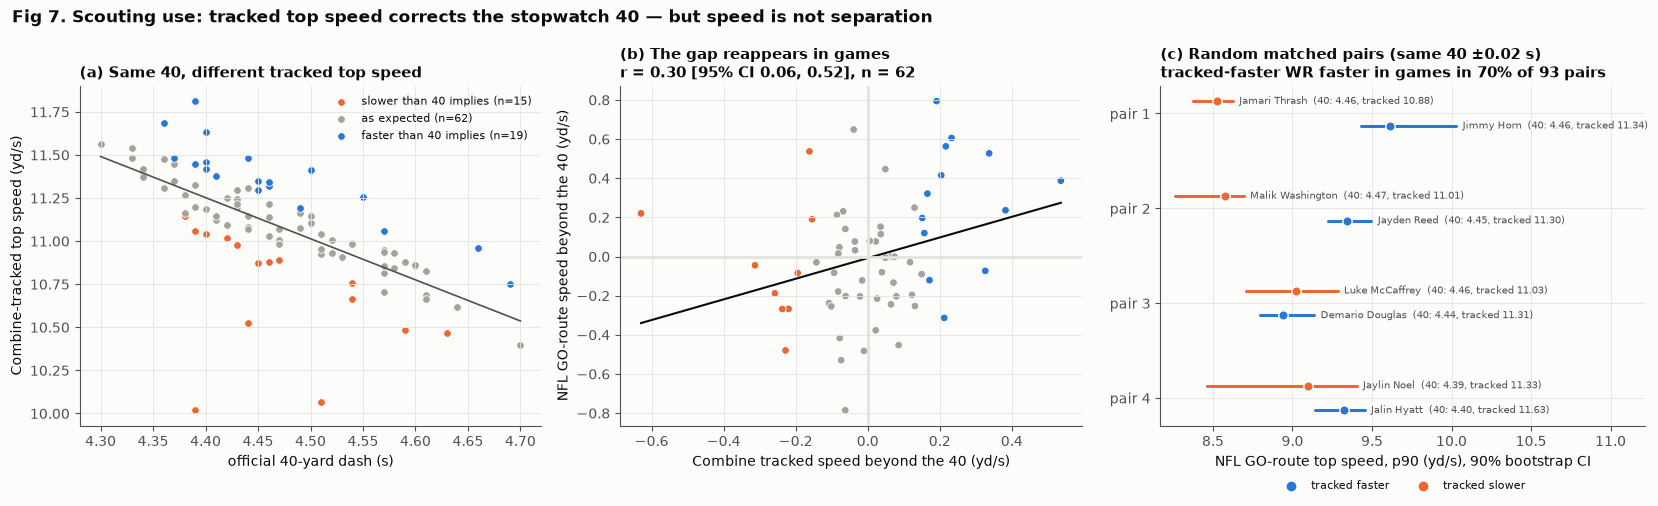

In [37]:
# ---- Scouting view: tracked top speed vs the stopwatch 40 ---------------------------------------
d = master.dropna(subset=["forty", "trk_top_speed"]).copy()
fit40 = np.polyfit(d.forty, d.trk_top_speed, 1)
d["trk_vs_forty"] = d.trk_top_speed - np.polyval(fit40, d.forty)
gm = d.dropna(subset=["g_top_speed"]).copy()
gfit = np.polyfit(gm.forty, gm.g_top_speed, 1); gm["game_vs_forty"] = gm.g_top_speed - np.polyval(gfit, gm.forty)
r_, p_ = stats.pearsonr(gm.trk_vs_forty, gm.game_vs_forty); lo_, hi_ = boot_corr(gm.trk_vs_forty, gm.game_vs_forty)
rho_ = stats.spearmanr(gm.trk_vs_forty, gm.game_vs_forty)
trim = gm[gm.trk_vs_forty.abs() < 0.6]
dd = gm[gm.routes >= MIN_ROUTES]
KEY.update(resid_r=r_, resid_p=p_, resid_lo=lo_, resid_hi=hi_, resid_n=len(gm), resid_rho=rho_[0],
           resid_trim_r=stats.pearsonr(trim.trk_vs_forty, trim.game_vs_forty)[0], resid_trim_n=len(trim),
           resid_soe_r=stats.pearsonr(dd.trk_vs_forty, dd.soe)[0], resid_soe_p=stats.pearsonr(dd.trk_vs_forty, dd.soe)[1], resid_soe_n=len(dd))
print(f"Tracked speed beyond the 40 vs game speed beyond the 40: r = {r_:.2f} [{lo_:.2f}, {hi_:.2f}], p = {p_:.4f}, n = {len(gm)}; "
      f"Spearman {rho_[0]:.2f}; trimmed r = {KEY['resid_trim_r']:.2f} (n = {len(trim)})")
print(f"Tracked speed beyond the 40 vs SOE: r = {KEY['resid_soe_r']:.2f}, p = {KEY['resid_soe_p']:.3f}, n = {len(dd)}")

# Per-player uncertainty: bootstrap the 90th-percentile GO-route peak speed; SOE posterior SD.
rng = np.random.default_rng(SEED); gci = {}
for pid, v in groutes[groutes.route_ran == "GO"].groupby("nfl_id").route_peak_speed:
    v = v.to_numpy()
    if len(v) >= 15:
        b = np.quantile(v[rng.integers(0, len(v), (1000, len(v)))], 0.9, axis=1); gci[pid] = np.percentile(b, [5, 95])
gm["g_lo"] = gm.nfl_id.map(lambda i: gci[i][0]); gm["g_hi"] = gm.nfl_id.map(lambda i: gci[i][1])
gm["soe_sd"] = np.sqrt(TAU2 * (1 - gm.reliability))

# Matched pairs (pre-declared rule): same 40 (|diff| <= 0.02 s), tracked top speed differs by >= 0.25 yd/s.
P = []
gl = gm.reset_index(drop=True)
for i in range(len(gl)):
    for j in range(i + 1, len(gl)):
        a, b = gl.loc[i], gl.loc[j]
        if abs(a.forty - b.forty) <= 0.02 and abs(a.trk_top_speed - b.trk_top_speed) >= 0.25:
            fast, slow = (a, b) if a.trk_top_speed > b.trk_top_speed else (b, a)
            P.append({"fast_id": fast.nfl_id, "slow_id": slow.nfl_id, "forty_fast": fast.forty, "forty_slow": slow.forty,
                      "trk_gap": fast.trk_top_speed - slow.trk_top_speed, "game_gap": fast.g_top_speed - slow.g_top_speed,
                      "ci_separated": fast.g_lo > slow.g_hi})
P = pd.DataFrame(P)
agree = (P.game_gap > 0).mean()
# Player-level permutation null for the agreement rate (pairs share players, so a binomial test is invalid)
perm = []
for _ in range(2000):
    sh = dict(zip(gl.nfl_id, rng.permutation(gl.g_top_speed.to_numpy())))
    perm.append(np.mean([sh[f] > sh[s] for f, s in zip(P.fast_id, P.slow_id)]))
p_perm = (np.sum(np.array(perm) >= agree) + 1) / (len(perm) + 1)
print(f"Matched pairs: {len(P)} (from {len(set(P.fast_id) | set(P.slow_id))} WRs). Tracked-faster WR also faster on NFL GO routes "
      f"in {agree:.0%} of pairs (permutation p = {p_perm:.3f}); mean game gap {P.game_gap.mean():+.2f} yd/s.")
KEY.update(pairs_n=len(P), pairs_agree=agree, pairs_p=p_perm, pairs_game_gap=P.game_gap.mean(), pairs_trk_gap=P.trk_gap.mean())
save_table(P, "25_matched_pairs")

# Example pairs: 4 drawn at random (seed) from qualifying pairs, no player reused — not the most extreme.
ex, used = [], set()
for k in rng.permutation(len(P)):
    row = P.iloc[k]
    if row.fast_id in used or row.slow_id in used: continue
    ex.append(row); used |= {row.fast_id, row.slow_id}
    if len(ex) == 4: break
ex = pd.DataFrame(ex)
info = gm.set_index("nfl_id")
prof = []
for _, rrow in ex.iterrows():
    for role, pid in [("tracked faster", rrow.fast_id), ("tracked slower", rrow.slow_id)]:
        z = info.loc[pid]
        prof.append({"pair": len(prof) // 2 + 1, "player": z.display_name, "draft": int(z.draft_year), "role": role,
                     "40 (s)": z.forty, "tracked top (yd/s)": z.trk_top_speed, "beyond 40 (yd/s)": z.trk_vs_forty,
                     "NFL GO p90 (yd/s)": z.g_top_speed, "90% CI": f"{z.g_lo:.2f}–{z.g_hi:.2f}", "GO routes": int(z.g_go_n),
                     "SOE (yd/route)": z.soe, "SOE ±SD": z.soe_sd, "routes": int(z.routes)})
profiles = save_table(pd.DataFrame(prof), "26_scouting_profiles"); display(profiles.round(2))
KEY["profiles"] = profiles.round(3).to_dict("records")

fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.05]})
cmap = {"slower than 40 implies": C2, "as expected": "#a3a29c", "faster than 40 implies": C1}
grp_lab = pd.cut(d.trk_vs_forty, [-np.inf, -0.15, 0.15, np.inf], labels=list(cmap))
for g_, sub in d.groupby(grp_lab, observed=True):
    ax[0].scatter(sub.forty, sub.trk_top_speed, color=cmap[g_], s=30, edgecolor="white", lw=.6, label=f"{g_} (n={len(sub)})")
xs = np.linspace(d.forty.min(), d.forty.max(), 50); ax[0].plot(xs, np.polyval(fit40, xs), color=INK2, lw=1.2)
ax[0].set_xlabel("official 40-yard dash (s)"); ax[0].set_ylabel("Combine-tracked top speed (yd/s)")
ax[0].legend(frameon=False, fontsize=8, loc="upper right"); ax[0].set_title("(a) Same 40, different tracked top speed", loc="left")
gcol = pd.cut(gm.trk_vs_forty, [-np.inf, -0.15, 0.15, np.inf], labels=list(cmap)).map(cmap)
ax[1].scatter(gm.trk_vs_forty, gm.game_vs_forty, c=list(gcol), s=30, edgecolor="white", lw=.6)
b1, b0 = np.polyfit(gm.trk_vs_forty, gm.game_vs_forty, 1); xs = np.linspace(gm.trk_vs_forty.min(), gm.trk_vs_forty.max(), 50)
ax[1].plot(xs, b0 + b1 * xs, color=INK, lw=1.5); ax[1].axhline(0, color=GRID); ax[1].axvline(0, color=GRID)
ax[1].set_xlabel("Combine tracked speed beyond the 40 (yd/s)"); ax[1].set_ylabel("NFL GO-route speed beyond the 40 (yd/s)")
ax[1].set_title(f"(b) The gap reappears in games\nr = {r_:.2f} [95% CI {lo_:.2f}, {hi_:.2f}], n = {len(gm)}", loc="left")
for k, (_, rrow) in enumerate(ex.iterrows()):
    for role, pid, c, off in [("faster", rrow.fast_id, C1, 0.13), ("slower", rrow.slow_id, C2, -0.13)]:
        z = info.loc[pid]; y = k + off
        ax[2].plot([z.g_lo, z.g_hi], [y, y], color=c, lw=2.2, solid_capstyle="round")
        ax[2].scatter(z.g_top_speed, y, color=c, s=46, zorder=3, edgecolor="white")
        ax[2].text(z.g_hi + 0.04, y, f"{z.display_name}  (40: {z.forty:.2f}, tracked {z.trk_top_speed:.2f})", va="center", fontsize=7.5, color=INK2)
ax[2].set_yticks(range(len(ex))); ax[2].set_yticklabels([f"pair {k+1}" for k in range(len(ex))]); ax[2].invert_yaxis()
ax[2].set_xlim(ax[2].get_xlim()[0], ax[2].get_xlim()[1] + 1.1)
ax[2].scatter([], [], color=C1, label="tracked faster"); ax[2].scatter([], [], color=C2, label="tracked slower")
ax[2].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
ax[2].set_xlabel("NFL GO-route top speed, p90 (yd/s), 90% bootstrap CI")
ax[2].set_title(f"(c) Random matched pairs (same 40 ±0.02 s)\ntracked-faster WR faster in games in {agree:.0%} of {len(P)} pairs", loc="left")
fig.suptitle("Fig 7. Scouting use: tracked top speed corrects the stopwatch 40 — but speed is not separation", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "fig7_scouting_profile")

**Results (Fig 7 and the profile table above).**
- **(b) The tracked correction reappears in games.** Tracked speed beyond what the 40 predicts correlates r = 0.30 (95% CI 0.06–0.52, n = 62) with NFL GO-route speed beyond what the 40 predicts (Spearman ρ = 0.31; trimmed r = 0.39).
- **(c) Matched pairs confirm it player by player.** Pairs were chosen by a fixed rule: same 40 within ±0.02 s, tracked top speed differing by ≥ 0.25 yd/s. Among 93 such pairs (42 WRs), the tracked-faster WR was faster on NFL GO routes in **70%** of pairs (player-level permutation p = 0.03), by +0.26 yd/s on average for a mean tracked gap of 0.43 yd/s.
- **The four example pairs** were drawn at random, not chosen as extremes, and they show the real spread. In pairs 1, 2 and 4 the tracked-faster player was faster in games; in pair 3 (Demario Douglas vs Luke McCaffrey) he was not, and the 90% CIs overlap. Wide CIs for players with few GO routes (e.g. Jimmy Horn: 17 GO routes) are a reminder that rookie game speed is itself noisy.
- **Speed is not separation.** The profile table shows SOE does not follow tracked speed (e.g. pair 2: Malik Washington tracked slower but has higher SOE than Jayden Reed). Overall, tracked speed beyond the 40 is only weakly related to SOE (r = 0.22, p = 0.08) and unrelated once size is adjusted for.

**How an evaluator or coach could use this:**
1. **Draft room.** When two WRs post the same 40, check the tracked Go-route/40 top speed. A gap of ≥ 0.25 yd/s is right about 7 times in 10 on which player will run faster in NFL games. Use it for *vertical-route projection*, not to rank overall receiver quality.
2. **Coaching and installation.** For a rookie whose tracked speed exceeds his 40, schedule more vertical/clear-out routes early; the tracker suggests his long speed is real. Do not expect that speed to show up as more separation at the throw, because in-game data show defenses neutralise it at the release point.
3. **Route-running evaluation.** Do not grade route running from single-rep Combine break or launch traces. Reliability of about 0.7 would need roughly 10 comparable reps per drill. Teams that want a Combine break metric should request repeated reps, or evaluate breaks from college game tracking with many reps.

These are illustrations, not rankings: no model showed reliable out-of-sample value for separation, so no prospect is labelled a future star or bust.

## 13. Verified data-flow diagram

Counts in each box are pulled from the executed linkage steps above.

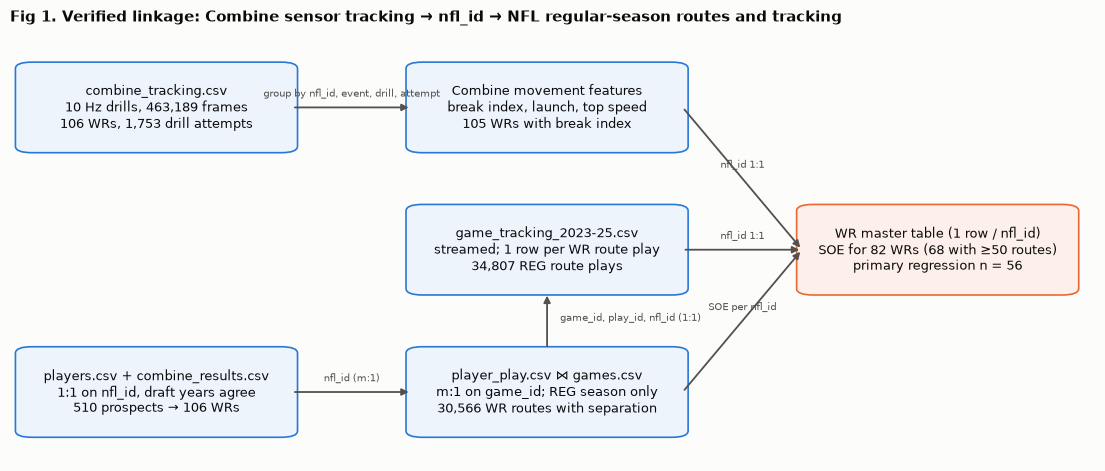

In [38]:
A = KEY["attrition"]
W, H = 0.25, 0.2
boxes = {
    "ct":  (0.01, 0.72, "combine_tracking.csv\n10 Hz drills, {:,} frames\n{} WRs, {:,} drill attempts".format(len(ct), ctw.nfl_id.nunique(), len(att))),
    "cr":  (0.01, 0.06, "players.csv + combine_results.csv\n1:1 on nfl_id, draft years agree\n{} prospects → {} WRs".format(len(players), len(wr))),
    "cf":  (0.37, 0.72, "Combine movement features\nbreak index, launch, top speed\n{} WRs with break index".format(A["  ...with >=1 detected hard-break drill (break_index)"])),
    "gt":  (0.37, 0.39, "game_tracking_2023-25.csv\nstreamed; 1 row per WR route play\n{:,} REG route plays".format(len(groutes))),
    "pp":  (0.37, 0.06, "player_play.csv ⋈ games.csv\nm:1 on game_id; REG season only\n{:,} WR routes with separation".format(KEY["sep_rows"])),
    "mt":  (0.73, 0.39, "WR master table (1 row / nfl_id)\nSOE for {} WRs ({} with ≥{} routes)\nprimary regression n = {}".format(
        KEY["sep_players"], KEY["soe_players_min"], MIN_ROUTES, KEY["prim_n"])),
}
fig, ax = plt.subplots(figsize=(14, 5.6)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
for k, (x, y, t) in boxes.items():
    fc = "#fdf0ea" if k == "mt" else "#eef4fc"
    ax.add_patch(FancyBboxPatch((x, y), W, H, boxstyle="round,pad=0.005,rounding_size=0.015", fc=fc, ec=C2 if k == "mt" else C1, lw=1.2))
    ax.text(x + W / 2, y + H / 2, t, ha="center", va="center", fontsize=9)
def link(src, dst, lab, side_src="r", side_dst="l", dy=0.025):
    xs, ys, _ = boxes[src]; xd, yd, _ = boxes[dst]
    p0 = {"r": (xs + W, ys + H / 2), "t": (xs + W / 2, ys + H), "b": (xs + W / 2, ys)}[side_src]
    p1 = {"l": (xd, yd + H / 2), "b": (xd + W / 2, yd), "t": (xd + W / 2, yd + H)}[side_dst]
    ax.annotate("", p1, p0, arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.3))
    ax.text((p0[0] + p1[0]) / 2 + (0.012 if side_src in "tb" else 0), (p0[1] + p1[1]) / 2 + (dy if side_src == "r" else 0),
            lab, fontsize=7.5, color=INK2, ha="left" if side_src in "tb" else "center")
link("ct", "cf", "group by nfl_id, event, drill, attempt")
link("cr", "pp", "nfl_id (m:1)")
link("pp", "gt", "game_id, play_id, nfl_id (1:1)", "t", "b")
link("cf", "mt", "nfl_id 1:1"); link("gt", "mt", "nfl_id 1:1"); link("pp", "mt", "SOE per nfl_id")
ax.set_title("Fig 1. Verified linkage: Combine sensor tracking → nfl_id → NFL regular-season routes and tracking", loc="left")
savefig(fig, "fig1_linkage")

## 14. Limitations and conclusion

**Limitations.**
- **Sample size and power:** 106 WRs, 68 with a stable SOE and 56 in the primary model. The power analysis (§9.1) shows only very large true effects of break skill were detectable; detecting a true r of 0.30 would need about 334 WRs.
- **Exposure and survivorship:** the 2025 class has one season. 24 WRs (mostly undrafted) have no regular-season routes, so conclusions apply to WRs who made the field.
- **Measurement:** about one rep per Combine drill. Break metrics are confounded by drill execution. Game break metrics depend on route depth and QB timing.
- **Outcome:** SOE measures getting open at the throw, not production (ρ ≈ 0.1 with targets and yards per route). It does not control for QB, scheme or defender identity, since defenders are not in the tracking files.
- **Generalisation:** three draft classes make LOYO noisy, and no external validation class exists yet. Matched pairs share players, which is why a permutation test was used. All results are associational.

**Conclusion.** Combine sensor tracking contains real, transferable signal, but in this data it is **speed, not breaks**.
Tracked top speed is reliable, reappears in NFL game tracking better than the 40, and picks the faster NFL player in
70% of same-40 matched pairs. Break mechanics could not be measured reliably from one Combine session, did not reappear
in NFL hitch routes, showed no positive association with route-adjusted separation, and were unrelated to
separation even when measured in games. No tracking feature consistently improved prediction of separation beyond
traditional Combine metrics, including with a fully fold-safe target and leave-one-draft-year-out validation.
**Actionable takeaway: use tracked top speed to refine the 40 for vertical-route projection, and do not over-read
single-rep Combine agility traces.**

## 15. Reproducibility notes and exported files

In [39]:
KEY_clean = json.loads(json.dumps(KEY, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
(OUT / "key_results.json").write_text(json.dumps(KEY_clean, indent=1))
import sklearn, statsmodels, scipy, matplotlib
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| statsmodels", statsmodels.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)
print("SEED =", SEED, "| MIN_ROUTES =", MIN_ROUTES)
for p in sorted(OUT.rglob("*.*")):
    print(f"{p.relative_to(OUT)}  ({p.stat().st_size/1e3:.0f} KB)")

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | statsmodels 0.15.0 | scipy 1.18.1 | matplotlib 3.11.2
SEED = 2027 | MIN_ROUTES = 50
figures/diag_feature_correlations.png  (189 KB)
figures/diag_fixed_target_models.png  (95 KB)
figures/diag_primary_model.png  (83 KB)
figures/fig1_linkage.png  (114 KB)
figures/fig2_break_detection.png  (303 KB)
figures/fig3_translation.png  (141 KB)
figures/fig4_soe_construction.png  (122 KB)
figures/fig5_association_forest.png  (94 KB)
figures/fig6_model_comparison.png  (122 KB)
figures/fig7_scouting_profile.png  (226 KB)
key_results.json  (20 KB)
tables/01_dataset_inventory.csv  (1 KB)
tables/02_data_dictionary.csv  (7 KB)
tables/03_combine_tracking_player_features.csv  (15 KB)
tables/04_combine_attempt_features.csv  (337 KB)
tables/05_game_tracking_player_features.csv  (5 KB)
tables/06_reliability.csv  (1 KB)
tables/07_wr_master_table.csv  (43 KB)
tables/08_attrition.csv  (0 KB)
tables/09_survivorship_check.csv  (1 KB)
tables/10_translation_combine_t

## 16. Submission checklist

| Item | Status |
|---|---|
| **Pass/fail 1:** explicit Combine sensor tracking → regular-season performance link | ✅ Combine tracking → `nfl_id` → regular-season separation (§3, §6, §9) and → regular-season game tracking (§8, §11b), with validated joins and an attrition table |
| **Pass/fail 2:** readable Markdown, embedded visuals, attached public notebook | ⚠️ Markdown and figures are embedded. **The notebook must still be made public on Kaggle and attached to the write-up.** |
| SOE definition and direction verified | ✅ §6 direction check (8/8 route types) |
| Combine → SOE beyond traditional metrics | ✅ §9 primary + secondary + robustness, with power/equivalence framing (§9.1) |
| Out-of-sample baseline vs tracking, LOYO | ✅ §10.1 and the fully fold-safe §10.2 with per-year bootstrap CIs |
| Leakage and selection | ✅ Draft-day predictors only (asserted), in-fold preprocessing, fold-safe target, one row per player, survivorship check (§7) |
| One defensible novel finding | ✅ Tracked top speed corrects the 40 (r = 0.30; 70% of matched pairs) |
| Player-level examples with uncertainty | ✅ Randomly drawn matched pairs with bootstrap CIs and SOE ± SD |
| Coaching application | ✅ §12 |
| Full rerun from a clean kernel | ✅ Executed top to bottom; outputs regenerated in `outputs/` |
| Write-up ≤ 2,000 words, < 10 figures/tables | ✅ `WRITEUP.md` |

**Remaining weaknesses by judging dimension (no score implied):**
- **Football:** the headline is partly negative. A scout's review of Fig 7 would strengthen the application.
- **Data science:** the cohort is small. A hierarchical Bayesian model and replication with DBs (who also run break drills) would add power.
- **Write-up:** keep the measure → transfer → value structure prominent.
- **Visualisation:** an interactive Fig 7 with per-prospect drill traces would help evaluators.